<small>
Introducción a la Ciencia de Datos | Posgrado en Ciencias de la Computación — CICESE
Práctica 4: Ensambles de clasificadores
</small>

# Práctica 4 — Ensambles de clasificadores

Como continuación de la Práctica 3, en esta práctica se busca responder una pregunta concreta: **¿cuánto ganan los ensambles sobre los cinco clasificadores base cuando estos ya están bien ajustados?** Para que la comparación sea justa se usa el mismo conjunto de deserción estudiantil, los mismos atributos y los mismos cinco pliegues estratificados de la Práctica 3. En la segunda parte se aplica todo lo aprendido a otro conjunto de datos, Bank Marketing, para ver si las conclusiones se mantienen en un problema distinto.

#### Descripción del problema e introducción

Un ensamble combina varios clasificadores para tomar una decisión mejor que la de cada uno por separado. No todos los ensambles hacen lo mismo; cada familia ataca una fuente de error distinta:

| Familia | Qué hace | Qué error ataca |
|---|---|---|
| **Bagging** | Entrena muchos modelos flexibles, cada uno con una muestra distinta de los datos, y promedia sus respuestas | La **varianza**: que el modelo cambie mucho cuando cambian los datos |
| **Boosting** | Entrena modelos débiles en secuencia, donde cada uno se enfoca en los errores de los anteriores | El **sesgo**: que el modelo sea demasiado simple para el problema |
| **Votación y stacking** | Combinan modelos que ya son distintos entre sí, por mayoría o con un meta-modelo | Los errores que un modelo comete y otro no |

En la Práctica 3 quedaron cinco clasificadores optimizados, y la regresión logística y el SVM terminaron prácticamente empatados con un F1 macro ≈ 0.68. A partir de ese punto se mide cuánto queda por ganar y si la respuesta cambia cuando el problema tiene otra estructura.

#### Descripción de los datasets

**Deserción estudiantil** (Parte 1)
- **Dataset:** Predict Students' Dropout and Academic Success (Realinho et al., 2021)
- **Unidad de observación:** un estudiante
- **Tamaño:** 3539 estudiantes con `Target`, 30 atributos conocidos al cierre del 1er semestre
- **Clases:** `graduate` (49.9 %), `dropout` (32.1 %), `enrolled` (17.9 %)

**Bank Marketing** (Parte 2)
- **Dataset:** `bank-additional-full.csv` (Moro et al., 2014)
- **Unidad de observación:** una llamada de telemarketing de un banco portugués (mayo de 2008 a noviembre de 2010)
- **Tamaño:** 41 188 llamadas, 19 atributos (sin `duration`, que solo se conoce después de la llamada)
- **Clases:** `no` (88.7 %), `yes` (11.3 %, el cliente contrata el depósito)

---

## 1. Configuración y carga de datos

En esta sección se prepara todo lo necesario para que los resultados sean comparables con los de la Práctica 3: las librerías, el estilo de las gráficas, los mismos datos y pliegues, y los cinco clasificadores base con sus mejores hiperparámetros.

### 1.1 Librerías y versiones

Además de las librerías de la Práctica 3, ahora se agregan **XGBoost** y **LightGBM** para el boosting optimizado, e **imbalanced-learn** para probar técnicas de remuestreo como SMOTE en Bank Marketing. Optuna ya no se necesita, porque el enunciado recomienda `RandomizedSearchCV` para las búsquedas de hiperparámetros.

In [2]:
import platform
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import xgboost
import lightgbm
import imblearn
import joblib

from joblib import Parallel, delayed
from scipy.stats import loguniform, randint, uniform

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.ensemble import (AdaBoostClassifier, BaggingClassifier, ExtraTreesClassifier,
                              RandomForestClassifier, StackingClassifier, VotingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score, make_scorer, recall_score
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold, TunedThresholdClassifierCV,
                                     cross_val_predict, cross_validate)
from sklearn.naive_bayes import CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import KBinsDiscretizer, LabelEncoder, OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as PipelineImb
from imblearn.under_sampling import RandomUnderSampler

In [3]:
print(f"Python       {platform.python_version()}")
for lib in (np, pd, matplotlib, sns, sklearn, xgboost, lightgbm, imblearn):
    print(f"{lib.__name__:12s} {lib.__version__}")

Python       3.14.10
numpy        2.5.4
pandas       3.1.0
matplotlib   3.11.2
seaborn      0.13.2
sklearn      1.9.1
xgboost      3.4.1
lightgbm     4.7.0
imblearn     0.14.2


**Qué hace el código.**

- Importa las librerías e imprime sus versiones. Se dejan registradas porque los resultados pueden cambiar ligeramente entre versiones, y así cualquiera puede reproducir el notebook en las mismas condiciones.

---

### 1.2 Estilo de gráficas y tablas

Se conserva el mismo estilo de la Práctica 3 para que las figuras de ambas prácticas se puedan comparar a simple vista: el mismo tema de seaborn, los mismos colores para entrenamiento y validación, el mismo mapa de color para las matrices de confusión y la función `mostrar`, que guarda cada gráfica en `Images/` con un nombre que empieza con el número de su sección.

In [4]:
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.dpi": 100,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.35,
    "legend.frameon": False,
})

COLOR_VALIDACION = "#4C72B0"
COLOR_ENTRENAMIENTO = "#C8553D"
COLOR_REFERENCIA = "#555555"
CMAP_CONF = "Blues"

CARPETA_IMG = Path("Images")
CARPETA_IMG.mkdir(exist_ok=True)

def mostrar(nombre):
    """Guarda la figura actual en Images/ como PNG y luego la muestra"""
    plt.savefig(CARPETA_IMG / f"{nombre}.png")
    plt.show()

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", "{:.4f}".format)
warnings.filterwarnings("ignore", message="Bins whose width are too small")

---

### 1.3 Datos de deserción y pliegues

Para que la comparación con la Práctica 3 sea válida, la preparación de los datos se repite exactamente igual. Si cambiara la semilla o los pliegues, una diferencia en el F1 podría deberse a la partición de los datos y no al modelo.

- Se usa `SEED = 67` y los mismos 30 atributos del 1er semestre, cada uno con el mismo tipo (nominal, binario, ordinal o numérico).
- Se usan los mismos cinco pliegues: `StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)`.
- La métrica principal sigue siendo el **F1 macro**. Además se agrega la **sensibilidad de `enrolled`**, porque en la Práctica 3 fue la clase más difícil de detectar y conviene seguirla de cerca.

In [5]:
SEED = 67
np.random.seed(SEED)

CARPETA_DATOS = Path("../../Datos")
des_train = pd.read_csv(CARPETA_DATOS / "Students Dropout" / "desercion-entrenamiento.csv", index_col="id")
des_test = pd.read_csv(CARPETA_DATOS / "Students Dropout" / "desercion-prueba.csv", index_col="id")
des_train["Target"] = des_train["Target"].str.lower()

cols_1er = [c for c in des_train.columns if c != "Target" and "2nd sem" not in c]
X = des_train[cols_1er]
y = des_train["Target"]
CLASES = sorted(y.unique())

NOMINALES = [
    "Marital status", "Application mode", "Course", "Previous qualification", "Nacionality",
    "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation",
]
BINARIOS = [
    "Daytime/evening attendance", "Displaced", "Educational special needs", "Debtor",
    "Tuition fees up to date", "Gender", "Scholarship holder", "International",
]
ORDINALES = ["Application order"]
NUMERICOS = [
    "Previous qualification (grade)", "Admission grade", "Age at enrollment",
    "Curricular units 1st sem (credited)", "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)", "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)", "Curricular units 1st sem (without evaluations)",
    "Unemployment rate", "Inflation rate", "GDP",
]
CONTINUOS = NUMERICOS + ORDINALES
assert len(NOMINALES + BINARIOS + CONTINUOS) == len(cols_1er) == 30

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
PLIEGUES = list(CV.split(X, y))
CV_INTERNO = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

ESCORES = {
    "f1": "f1_macro",
    "sens": make_scorer(recall_score, labels=["enrolled"], average="macro", zero_division=0),
}

print("X:", X.shape, " Clases:", CLASES)

X: (3539, 30)  Clases: ['dropout', 'enrolled', 'graduate']


---

### 1.4 Los cinco clasificadores base

Los cinco clasificadores se recuperan con el preprocesamiento y los hiperparámetros que resultaron mejores en la Práctica 3. La optimización no se repite: el objetivo es partir de modelos que ya están bien ajustados y medir qué agregan los ensambles sobre ellos.

| Modelo | Preprocesamiento | Hiperparámetros |
|---|---|---|
| Regresión logística | One-hot y `StandardScaler` | `C=0.191`, `l1_ratio=0.507`, `class_weight="balanced"` |
| SVM | One-hot y `StandardScaler` | RBF, `C=1.614`, `gamma=0.0256`, `class_weight="balanced"` |
| kNN | One-hot y `StandardScaler` | `n_neighbors=7`, `p=1`, `weights="uniform"` |
| Árbol de decisión | Ninguno | `max_depth=20`, `min_samples_leaf=19`, `ccp_alpha=0.0049`, `gini` |
| Naive Bayes | Ordinal y 12 intervalos | `CategoricalNB`, `alpha=0.445` |

In [6]:
CATEGORICAS = [sorted(set(des_train[c]) | set(des_test[c])) for c in NOMINALES]

def prep_escalado():
    """Preprocesamiento de regresion logistica, SVM y kNN"""
    one_hot = OneHotEncoder(min_frequency=30, handle_unknown="infrequent_if_exist", sparse_output=False)
    return ColumnTransformer([
        ("nominales", one_hot, NOMINALES),
        ("continuos", StandardScaler(), CONTINUOS),
        ("binarios", "passthrough", BINARIOS),
    ])

def prep_categorico(n_bins):
    """Preprocesamiento de CategoricalNB: todo a enteros 0, 1, 2..."""
    return ColumnTransformer([
        ("nominales", OrdinalEncoder(categories=CATEGORICAS), NOMINALES),
        ("binarios", "passthrough", BINARIOS),
        ("continuos", KBinsDiscretizer(n_bins, encode="ordinal", strategy="quantile"), CONTINUOS),
    ])

min_categorias = [len(c) for c in CATEGORICAS] + [2] * len(BINARIOS) + [12] * len(CONTINUOS)

logistica = Pipeline([("prep", prep_escalado()), ("modelo", LogisticRegression(
    C=0.19140281435904047, l1_ratio=0.5070810191014391, class_weight="balanced",
    solver="saga", max_iter=2000, tol=1e-3, random_state=SEED))])
svm = Pipeline([("prep", prep_escalado()), ("modelo", SVC(
    kernel="rbf", C=1.614029086528123, gamma=0.02556814549636102, class_weight="balanced",
    cache_size=1000, random_state=SEED))])
knn = Pipeline([("prep", prep_escalado()), ("modelo", KNeighborsClassifier(n_neighbors=7, weights="uniform", p=1))])
arbol = Pipeline([("modelo", DecisionTreeClassifier(
    max_depth=20, min_samples_leaf=19, ccp_alpha=0.0049299250581314345, criterion="gini",
    class_weight=None, random_state=SEED))])
naive_bayes = Pipeline([("prep", prep_categorico(12)), ("modelo", CategoricalNB(
    alpha=0.4448636561609948, fit_prior=True, min_categories=min_categorias))])

BASE = {"Regresion logistica": logistica, "SVM": svm, "kNN": knn, "Arbol de decision": arbol, "Naive Bayes": naive_bayes}

**Qué hace el código.**

- Reconstruye los preprocesamientos de la Práctica 3 y arma los cinco pipelines con sus mejores hiperparámetros. Los valores se escriben directamente en el código, ya que no se repite la búsqueda.

---

### 1.5 Funciones de evaluación

Como en esta práctica se evalúan decenas de modelos, conviene definir una sola vez las funciones que los evalúan y guardan sus resultados. Así todos los modelos se miden exactamente de la misma forma y al final se pueden reunir en una sola tabla.

| Función | Qué hace | Por qué |
|---|---|---|
| `evaluar` | Aplica `cross_validate` con los pliegues del conjunto y guarda el F1, la sensibilidad y el tiempo | El tiempo que se guarda es el **promedio de entrenamiento por pliegue**, que sirve para comparar modelos aunque dependa de la carga de la computadora |
| `buscar` | Hace la búsqueda con `RandomizedSearchCV` y guarda la mejor configuración y todas las probadas | Permite reportar la mejor configuración y después graficar la meseta |
| `grafica_meseta` | Dibuja el mejor F1 acumulado y el F1 contra un hiperparámetro | Son los mismos dos paneles de la Práctica 3, para ver si la búsqueda ya se estabilizó |
| `ConPesos` | Convierte los pesos por clase en `sample_weight` y codifica las etiquetas | XGBoost no acepta `class_weight` y necesita etiquetas enteras; así XGBoost y LightGBM se usan con la misma interfaz |

Los modelos corren con un solo núcleo porque lo que se paraleliza son los pliegues (`n_jobs=-1`). 

In [ ]:
class ConPesos(ClassifierMixin, BaseEstimator):
    """Da a XGBoost o LightGBM etiquetas enteras y pesos por clase"""

    def __init__(self, estimador, class_weight=None):
        self.estimador = estimador
        self.class_weight = class_weight

    def fit(self, X, y):
        self.codificador_ = LabelEncoder().fit(y)
        self.classes_ = self.codificador_.classes_
        pesos = compute_sample_weight(self.class_weight, y)
        self.modelo_ = clone(self.estimador).fit(X, self.codificador_.transform(y), sample_weight=pesos)
        return self

    def predict_proba(self, X):
        return self.modelo_.predict_proba(X)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


DESERCION = {"nombre": "desercion", "X": X, "y": y, "pliegues": PLIEGUES, "escores": ESCORES, "seed": SEED, "tabla": {}}

def evaluar(nombre, modelo, familia, datos, config=""):
    """Validacion cruzada de un modelo con los pliegues del conjunto"""
    r = cross_validate(modelo, datos["X"], datos["y"], cv=datos["pliegues"], scoring=datos["escores"], n_jobs=-1)
    datos["tabla"][nombre] = {"familia": familia, "f1": r["test_f1"], "sens": r["test_sens"].mean(),
                              "tiempo": r["fit_time"].mean(), "config": config, "estimador": modelo}
    print(f"{nombre:38s} F1 = {r['test_f1'].mean():.4f} +- {r['test_f1'].std():.4f}"
          f"   sens = {r['test_sens'].mean():.3f}   tiempo = {r['fit_time'].mean():.2f} s")

def texto_config(params):
    """Mejor configuracion en texto corto"""
    partes = []
    for k, v in params.items():
        k = k.replace("modelo__", "").replace("estimador__", "")
        partes.append(f"{k}={float(v):.3g}" if isinstance(v, (float, np.floating)) else f"{k}={v}")
    return ", ".join(partes)

def buscar(nombre, modelo, distribuciones, familia, datos, n_iter=60):
    """Busqueda aleatoria de hiperparametros con los pliegues del conjunto"""
    busqueda = RandomizedSearchCV(modelo, distribuciones, n_iter=n_iter, scoring=datos["escores"], refit=False,
                                  cv=datos["pliegues"], random_state=datos["seed"], n_jobs=-1)
    inicio = time.perf_counter()
    busqueda.fit(datos["X"], datos["y"])
    duracion = time.perf_counter() - inicio

    res = pd.DataFrame(busqueda.cv_results_)
    i = res["mean_test_f1"].idxmax()
    params = res.iloc[i]["params"] # type: ignore
    f1 = np.array([res.loc[i, f"split{k}_test_f1"] for k in range(5)]) # type: ignore
    datos["tabla"][nombre] = {"familia": familia, "f1": f1, "sens": res.loc[i, "mean_test_sens"], # type: ignore
                              "tiempo": res.loc[i, "mean_fit_time"], "config": texto_config(params), # type: ignore
                              "estimador": clone(modelo).set_params(**params), "busqueda": res}
    print(f"{nombre}: {n_iter} configuraciones en {duracion:.0f} s")
    print(f"Mejor F1 macro: {f1.mean():.4f} +- {f1.std():.4f}")
    print("Mejor configuracion:", texto_config(params))
    print(f"Encontrada en la configuracion {i + 1}. Las cinco mejores:", res["mean_test_f1"].nlargest(5).round(4).tolist()) # type: ignore

def grafica_meseta(nombre, datos, param, seccion, separar_por="class_weight", log=False):
    """Izquierda: mejor F1 acumulado. Derecha: F1 de cada configuracion contra un hiperparametro."""
    res = datos["tabla"][nombre]["busqueda"]
    f1 = res["mean_test_f1"]
    mejor = f1.cummax()
    y_min, y_max = f1.quantile(0.1) - 0.01, mejor.max() + 0.01
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].scatter(res.index + 1, f1, s=15, alpha=0.4, color=COLOR_VALIDACION, label="cada configuracion")
    axes[0].plot(res.index + 1, mejor, color=COLOR_VALIDACION, lw=2, label="mejor hasta el momento")
    axes[0].set(ylim=(y_min, y_max), xlabel="configuraciones evaluadas", ylabel="F1 macro (validacion)",
                title=f"{nombre}: mejor F1 acumulado")
    axes[0].legend(loc="lower right")

    sns.scatterplot(x=pd.to_numeric(res[f"param_{param}"]), y=f1, hue=res[f"param_{separar_por}"].map(str).replace("nan", "None"),
                    s=25, alpha=0.7, ax=axes[1])
    if log:
        axes[1].set_xscale("log")
    etiqueta = param.split("__")[-1]
    axes[1].set(ylim=(y_min, y_max), xlabel=etiqueta, ylabel="F1 macro (validacion)", title=f"{nombre}: F1 contra {etiqueta}")
    axes[1].legend(title=separar_por.split("__")[-1], loc="lower right", fontsize=8)
    plt.tight_layout()
    mostrar(f"{seccion}_meseta_{datos['nombre']}_{nombre.lower().replace(' ', '_').replace('-', '_')}_{etiqueta}")

def tabla_resultados(datos, sensibilidad):
    """Todos los modelos de un conjunto, ordenados por F1 macro"""
    filas = []
    for nombre, r in datos["tabla"].items():
        filas.append([nombre, r["familia"], r["f1"].mean(), r["f1"].std(), r["sens"], r["tiempo"], r["config"]])
    columnas = ["modelo", "familia", "F1 macro (media)", "F1 macro (desv.)", sensibilidad, "tiempo (s)", "mejor configuracion"]
    return pd.DataFrame(filas, columns=columnas).sort_values("F1 macro (media)", ascending=False).reset_index(drop=True)


for nombre, modelo in BASE.items():
    evaluar(nombre, modelo, "Base (P3)", DESERCION)

F1_P3 = {"Regresion logistica": 0.6854, "SVM": 0.6820, "kNN": 0.5733, "Arbol de decision": 0.6408, "Naive Bayes": 0.6320}
for nombre, valor in F1_P3.items():
    assert abs(DESERCION["tabla"][nombre]["f1"].mean() - valor) < 1e-3, f"{nombre} no reproduce la Practica 3"
print("Los cinco modelos reproducen el F1 de la Practica 3")

Regresion logistica                    F1 = 0.6854 +- 0.0185   sens = 0.581   tiempo = 0.64 s
SVM                                    F1 = 0.6820 +- 0.0216   sens = 0.581   tiempo = 0.52 s
kNN                                    F1 = 0.5733 +- 0.0153   sens = 0.238   tiempo = 0.07 s
Arbol de decision                      F1 = 0.6408 +- 0.0307   sens = 0.365   tiempo = 0.03 s
Naive Bayes                            F1 = 0.6320 +- 0.0114   sens = 0.422   tiempo = 0.04 s
Los cinco modelos reproducen el F1 de la Practica 3


**Qué hace el código.**

- Define `ConPesos`, `evaluar`, `buscar`, `grafica_meseta` y `tabla_resultados`.
- Evalúa los cinco modelos base y comprueba con un `assert` que reproducen el F1 macro de la Práctica 3. Si algún modelo no lo reprodujera, el notebook se detendría aquí, porque todas las comparaciones siguientes dependen de que el punto de partida sea el mismo.

---

## 2. Varianza: árbol sin límite y bagging

En esta sección se estudia qué hace bagging y por qué funciona. Para eso se parte de un modelo con **mucha varianza**: un árbol de decisión sin límite de profundidad. Este árbol puede crecer hasta memorizar el entrenamiento, por lo que tiene poco sesgo, pero cambia mucho si cambian los datos.

Bagging entrena muchos de estos árboles, cada uno con una muestra *bootstrap* (una muestra con reemplazo del mismo tamaño que el entrenamiento), y promedia sus probabilidades. Para construir la curva contra el número de árboles se usa `warm_start=True`: cada vez que aumenta `n_estimators`, solo se entrenan los árboles nuevos y se conservan los anteriores, en lugar de volver a entrenar todo desde cero.

Arbol sin limite                       F1 = 0.5890 +- 0.0136   sens = 0.329   tiempo = 0.06 s
Bagging (400 arboles)                  F1 = 0.6577 +- 0.0071   sens = 0.323   tiempo = 5.34 s


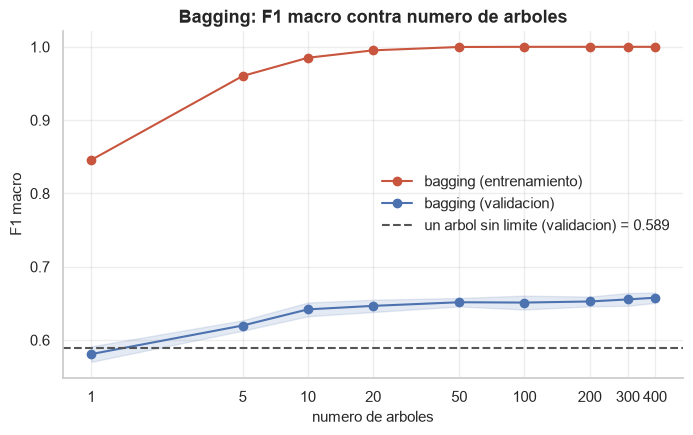

,arboles,F1 entrenamiento,F1 validacion,desv. validacion
0,1,0.8457,0.5809,0.0106
1,5,0.9602,0.6198,0.0071
2,10,0.9851,0.6418,0.0094
3,20,0.9952,0.6466,0.0083
4,50,0.9998,0.6516,0.0058
5,100,1.0000,0.6511,0.0095
6,200,1.0000,0.6526,0.0066
7,300,1.0000,0.6555,0.0087
8,400,1.0000,0.6577,0.0071


In [8]:
NUM_ARBOLES = [1, 5, 10, 20, 50, 100, 200, 300, 400]

def curva_bagging(idx_entr, idx_val):
    """F1 de entrenamiento y validacion de bagging en un pliegue, agregando arboles"""
    bag = BaggingClassifier(DecisionTreeClassifier(random_state=SEED), warm_start=True, random_state=SEED)
    filas = []
    for n in NUM_ARBOLES:
        bag.set_params(n_estimators=n).fit(X.iloc[idx_entr], y.iloc[idx_entr])
        filas.append([f1_score(y.iloc[idx_entr], bag.predict(X.iloc[idx_entr]), average="macro"),
                      f1_score(y.iloc[idx_val], bag.predict(X.iloc[idx_val]), average="macro")])
    return filas

curvas_bag = np.array(Parallel(n_jobs=5)(delayed(curva_bagging)(e, v) for e, v in PLIEGUES))
f1_bag_entr, f1_bag_val = curvas_bag[:, :, 0], curvas_bag[:, :, 1]

arbol_libre = DecisionTreeClassifier(random_state=SEED)
evaluar("Arbol sin limite", arbol_libre, "Varianza", DESERCION)
evaluar("Bagging (400 arboles)", BaggingClassifier(arbol_libre, n_estimators=400, random_state=SEED), "Varianza", DESERCION)
f1_arbol = DESERCION["tabla"]["Arbol sin limite"]["f1"].mean()

plt.figure()
plt.plot(NUM_ARBOLES, f1_bag_entr.mean(axis=0), "o-", color=COLOR_ENTRENAMIENTO, label="bagging (entrenamiento)")
plt.plot(NUM_ARBOLES, f1_bag_val.mean(axis=0), "o-", color=COLOR_VALIDACION, label="bagging (validacion)")
plt.fill_between(NUM_ARBOLES, f1_bag_val.mean(axis=0) - f1_bag_val.std(axis=0),
                 f1_bag_val.mean(axis=0) + f1_bag_val.std(axis=0), color=COLOR_VALIDACION, alpha=0.15)
plt.axhline(f1_arbol, color=COLOR_REFERENCIA, ls="--", label=f"un arbol sin limite (validacion) = {f1_arbol:.3f}")
plt.xscale("log")
plt.xticks(NUM_ARBOLES, [str(n) for n in NUM_ARBOLES])
plt.minorticks_off()
plt.xlabel("numero de arboles")
plt.ylabel("F1 macro")
plt.title("Bagging: F1 macro contra numero de arboles")
plt.legend()
mostrar("2_bagging_curva")

pd.DataFrame({"arboles": NUM_ARBOLES, "F1 entrenamiento": f1_bag_entr.mean(axis=0),
              "F1 validacion": f1_bag_val.mean(axis=0), "desv. validacion": f1_bag_val.std(axis=0)})

**Qué hace el código.**

- `curva_bagging` va agregando árboles en un pliegue con `warm_start=True` y mide el F1 en entrenamiento y en validación para 1, 5, 10, 20, 50, 100, 200, 300 y 400 árboles. Los cinco pliegues corren en paralelo.
- Evalúa el árbol sin límite y el bagging de 400 árboles con `evaluar`, y dibuja la curva. La banda sombreada es ±1 desviación estándar entre pliegues.

**Lectura.** Un solo árbol sin límite logra un F1 de 0.589 en validación, y al promediar 400 árboles se llega a 0.658, una mejora de +0.069. Casi toda esa ganancia ocurre al principio: con 50 árboles ya se alcanza 0.652, y de ahí a 400 solo se suman 0.006 más. Es decir, agregar árboles ayuda mucho al inicio y después la curva se aplana.

Llama la atención que un solo árbol de bagging (0.581) es un poco peor que el árbol completo. Esto tiene sentido, porque su muestra *bootstrap* contiene solo ≈ 63 % de los estudiantes distintos; el resto son repeticiones. Cada árbol por separado ve menos información, pero al promediarlos se compensa con creces.

### 2.1 Medición directa de la varianza

La curva anterior muestra que el F1 mejora, pero no demuestra que la causa sea una reducción de la varianza. Para comprobarlo se mide la varianza directamente.

La idea es la siguiente: un modelo con mucha varianza "cambia de opinión" cuando cambian los datos con los que se entrena. Entonces se entrena cada modelo 10 veces con submuestras distintas del mismo entrenamiento y se cuenta **en qué fracción de los estudiantes de validación dos réplicas predicen una clase distinta**. Entre más alto sea ese desacuerdo, más varianza tiene el modelo.

In [ ]:
def desacuerdo(modelo, idx_entr, idx_val, replicas=10):
    """Fraccion de estudiantes en que dos replicas del modelo predicen distinto"""
    rng = np.random.RandomState(SEED)
    preds = []
    for r in range(replicas):
        muestra = rng.choice(idx_entr, size=int(0.8 * len(idx_entr)), replace=False)
        m = clone(modelo).set_params(random_state=r)
        preds.append(m.fit(X.iloc[muestra], y.iloc[muestra]).predict(X.iloc[idx_val]))
    return np.mean([(preds[i] != preds[j]).mean() for i in range(replicas) for j in range(i + 1, replicas)])

filas = []
for nombre, modelo in [("Arbol sin limite", arbol_libre),
                       ("Bagging (100 arboles)", BaggingClassifier(arbol_libre, n_estimators=100))]:
    d = Parallel(n_jobs=5)(delayed(desacuerdo)(modelo, e, v) for e, v in PLIEGUES)
    filas.append([nombre, np.mean(d), np.std(d)]) # type: ignore
pd.DataFrame(filas, columns=["modelo", "desacuerdo entre replicas", "desv. entre pliegues"])

,modelo,desacuerdo entre replicas,desv. entre pliegues
0,Arbol sin limite,0.3366,0.0072
1,Bagging (100 arboles),0.0957,0.0040


**Qué hace el código.**

- `desacuerdo` entrena 10 copias del modelo, cada una con una submuestra del 80 % del entrenamiento, y promedia sobre todos los pares de copias la fracción de predicciones distintas en validación.
- Lo calcula en los cinco pliegues, tanto para el árbol como para bagging. Para bagging se usan 100 árboles en lugar de 400, porque la curva ya está casi plana en ese punto y así el cálculo no se alarga.

**Lectura. ¿Qué reduce bagging, y por qué?** Bagging reduce la **varianza**, y la medición lo confirma de forma clara: dos árboles entrenados con submuestras distintas predicen una clase diferente en el 33.7 % de los estudiantes, mientras que dos ensambles de 100 árboles solo difieren en el 9.6 %.

**¿Por qué pasa esto?** Cada árbol sobreajusta a su propia muestra, pero los errores que comete cambian de una muestra a otra, así que al promediarlos se cancelan en parte. Esto se puede expresar con una fórmula: si se tienen B árboles, cada uno con varianza σ² y una correlación ρ entre ellos, la varianza del promedio es ρσ² + (1 − ρ)σ²/B. El segundo término desaparece conforme se agregan árboles, pero el primero no depende de B. Por eso la curva llega a una meseta: lo que queda es la parte de los errores que todos los árboles comparten.

**¿Qué no reduce?** El F1 de entrenamiento se queda en 1.0, porque cada árbol ya tenía muy poco sesgo y no había nada que corregir ahí. Tampoco mejora la clase difícil: la sensibilidad de `enrolled` queda prácticamente igual (0.329 contra 0.323), ya que promediar árboles no compensa el desbalance entre clases.

---

## 3. Sesgo: tocón y AdaBoost

Ahora se hace el ejercicio contrario: se parte de un modelo con **mucho sesgo** para ver qué hace boosting. Ese modelo es un **tocón**, un árbol de profundidad 1 que hace una sola pregunta sobre un solo atributo. Es muy estable, pero demasiado simple. De hecho, como solo tiene dos hojas, solo puede predecir dos de las tres clases.

AdaBoost entrena tocones en secuencia. Después de cada ronda aumenta el peso de los estudiantes que quedaron mal clasificados, de modo que el siguiente tocón se enfoca en ellos, y al final combina todos los tocones en un voto ponderado. Para obtener la curva contra el número de rondas se usa `staged_predict`, que devuelve la predicción después de cada ronda sin tener que volver a entrenar el modelo.

Tocon                                  F1 = 0.4920 +- 0.0112   sens = 0.000   tiempo = 0.06 s
AdaBoost (400 tocones)                 F1 = 0.6308 +- 0.0242   sens = 0.247   tiempo = 3.79 s


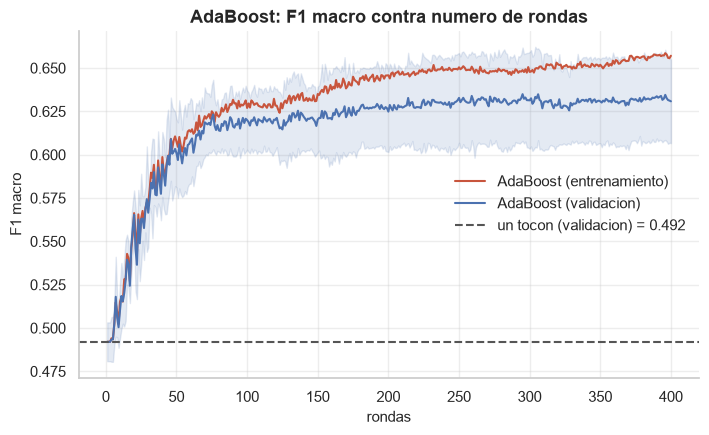

,rondas,F1 entrenamiento,F1 validacion
0,1,0.4920,0.4920
1,5,0.4935,0.4934
2,10,0.5150,0.5101
3,20,0.5663,0.5653
4,50,0.6074,0.6009
5,100,0.6270,0.6200
6,200,0.6458,0.6249
7,300,0.6478,0.6314
8,400,0.6571,0.6308


In [10]:
RONDAS = 400
tocon = DecisionTreeClassifier(max_depth=1, random_state=SEED)

def curva_adaboost(idx_entr, idx_val):
    """F1 de entrenamiento y validacion de AdaBoost despues de cada ronda, en un pliegue"""
    X_entr, X_val = X.iloc[idx_entr].to_numpy(), X.iloc[idx_val].to_numpy()
    y_entr, y_val = y.iloc[idx_entr], y.iloc[idx_val]
    ada = AdaBoostClassifier(tocon, n_estimators=RONDAS, random_state=SEED).fit(X_entr, y_entr)
    return ([f1_score(y_entr, p, average="macro") for p in ada.staged_predict(X_entr)],
            [f1_score(y_val, p, average="macro") for p in ada.staged_predict(X_val)])

curvas_ada = np.array(Parallel(n_jobs=5)(delayed(curva_adaboost)(e, v) for e, v in PLIEGUES))
f1_ada_entr, f1_ada_val = curvas_ada[:, 0, :], curvas_ada[:, 1, :]

evaluar("Tocon", tocon, "Sesgo", DESERCION)
evaluar("AdaBoost (400 tocones)", AdaBoostClassifier(tocon, n_estimators=RONDAS, random_state=SEED), "Sesgo", DESERCION)
f1_tocon = DESERCION["tabla"]["Tocon"]["f1"].mean()

rondas = np.arange(1, RONDAS + 1)
plt.figure()
plt.plot(rondas, f1_ada_entr.mean(axis=0), color=COLOR_ENTRENAMIENTO, label="AdaBoost (entrenamiento)")
plt.plot(rondas, f1_ada_val.mean(axis=0), color=COLOR_VALIDACION, label="AdaBoost (validacion)")
plt.fill_between(rondas, f1_ada_val.mean(axis=0) - f1_ada_val.std(axis=0),
                 f1_ada_val.mean(axis=0) + f1_ada_val.std(axis=0), color=COLOR_VALIDACION, alpha=0.15)
plt.axhline(f1_tocon, color=COLOR_REFERENCIA, ls="--", label=f"un tocon (validacion) = {f1_tocon:.3f}")
plt.xlabel("rondas")
plt.ylabel("F1 macro")
plt.title("AdaBoost: F1 macro contra numero de rondas")
plt.legend()
mostrar("3_adaboost_curva")

marcas = [1, 5, 10, 20, 50, 100, 200, 300, 400]
pd.DataFrame({"rondas": marcas, "F1 entrenamiento": f1_ada_entr.mean(axis=0)[np.array(marcas) - 1],
              "F1 validacion": f1_ada_val.mean(axis=0)[np.array(marcas) - 1]})

**Qué hace el código.**

- `curva_adaboost` entrena AdaBoost con 400 rondas una sola vez por pliegue y usa `staged_predict` para medir el F1 en entrenamiento y en validación después de cada ronda.
- Evalúa el tocón y AdaBoost con `evaluar`, y dibuja las curvas de entrenamiento y validación junto con la línea del tocón como referencia.

**Lectura. ¿Qué reduce boosting, y por qué?** Boosting reduce el **sesgo**. El tocón logra un F1 de 0.492 tanto en entrenamiento como en validación. Que ambos valores sean iguales indica que no está sobreajustando; simplemente es demasiado simple para representar el problema. Además, su sensibilidad de `enrolled` es 0, porque con dos hojas nunca predice esa clase. AdaBoost sube las dos curvas al mismo tiempo, hasta 0.657 en entrenamiento y 0.631 en validación.

**¿Por qué pasa esto?** Cada ronda aumenta el peso de los estudiantes mal clasificados, así que el siguiente tocón se concentra en lo que los anteriores no lograron resolver. Un solo corte solo puede dividir los datos en dos, pero la suma ponderada de muchos cortes forma una frontera mucho más compleja.

**La firma es opuesta a la de bagging.** En bagging, el entrenamiento ya era perfecto desde el inicio y solo mejoraba la validación. Aquí, en cambio, las dos curvas suben juntas: la brecha entre ellas es de solo ≈ 0.006 en la ronda 50 y crece a 0.026 en la ronda 400, cuando la validación ya casi no mejora. Esa brecha creciente es el inicio del sobreajuste.

**Límites.** Aun con 400 tocones, AdaBoost no alcanza a los mejores modelos base, y la sensibilidad de `enrolled` se queda en 0.247.

---

## 4. Combinar los cinco modelos base

En esta sección ya no se parte de un modelo débil, sino de los cinco modelos base de la Práctica 3, que ya son distintos entre sí. La pregunta es si combinarlos da un mejor resultado que el mejor de ellos. Se prueban tres formas de combinarlos:

| Método | Cómo decide | Qué necesita |
|---|---|---|
| **Votación dura** | Gana la clase con más votos | Solo la predicción de cada modelo, así que usa el SVM original |
| **Votación suave** | Promedia las probabilidades y elige la clase con el promedio más alto | Probabilidades de los cinco modelos |
| **Stacking** | Un meta-modelo logístico aprende cómo combinar las probabilidades de los cinco | Probabilidades obtenidas fuera de muestra dentro de cada entrenamiento (`cv=CV_INTERNO`), para que el meta-modelo no aprenda de modelos que ya vieron esos mismos datos |

**Probabilidades del SVM.** `SVC` no da probabilidades por defecto, así que se envuelve en `CalibratedClassifierCV(svm, cv=CV_INTERNO)`, que las obtiene con una calibración sigmoide. Como `cross_validate` llama a su `fit` solo con el 80 % de entrenamiento de cada pliegue, la calibración nunca ve el pliegue de validación.

El enunciado pide un meta-modelo logístico. Se evalúa sin pesos y también con `class_weight="balanced"`, ya que en la Práctica 3 compensar el desbalance fue una de las decisiones más importantes.

In [11]:
svm_calibrado = CalibratedClassifierCV(svm, method="sigmoid", cv=CV_INTERNO)

SIN_CALIBRAR = [("logistica", logistica), ("svm", svm), ("knn", knn), ("arbol", arbol), ("nb", naive_bayes)]
CON_PROBA = [("logistica", logistica), ("svm", svm_calibrado), ("knn", knn), ("arbol", arbol), ("nb", naive_bayes)]

evaluar("SVM calibrado", svm_calibrado, "Combinacion", DESERCION)
evaluar("Votacion dura", VotingClassifier(SIN_CALIBRAR, voting="hard"), "Combinacion", DESERCION) # type: ignore
evaluar("Votacion suave", VotingClassifier(CON_PROBA, voting="soft"), "Combinacion", DESERCION)
evaluar("Stacking (meta sin pesos)", StackingClassifier(
    CON_PROBA, final_estimator=LogisticRegression(max_iter=2000), cv=CV_INTERNO, stack_method="predict_proba"),
    "Combinacion", DESERCION)
evaluar("Stacking (meta balanced)", StackingClassifier(
    CON_PROBA, final_estimator=LogisticRegression(max_iter=2000, class_weight="balanced"), cv=CV_INTERNO,
    stack_method="predict_proba"), "Combinacion", DESERCION)

SVM calibrado                          F1 = 0.6605 +- 0.0211   sens = 0.307   tiempo = 2.66 s
Votacion dura                          F1 = 0.6814 +- 0.0193   sens = 0.494   tiempo = 1.50 s
Votacion suave                         F1 = 0.6683 +- 0.0196   sens = 0.364   tiempo = 2.63 s
Stacking (meta sin pesos)              F1 = 0.6648 +- 0.0164   sens = 0.334   tiempo = 14.08 s
Stacking (meta balanced)               F1 = 0.6872 +- 0.0167   sens = 0.594   tiempo = 13.97 s


**Qué hace el código.**

- Envuelve el SVM en `CalibratedClassifierCV` y lo evalúa solo, para medir por separado qué efecto tiene la calibración.
- Evalúa las dos votaciones y los dos stackings con los mismos cinco pliegues, mediante `cross_validate`.

**Lectura.** De las combinaciones, solo el stacking con pesos alcanza a la regresión logística (0.687 contra 0.685), y la diferencia es mínima.

Lo más informativo de esta sección es el **efecto de la calibración** sobre el SVM: su F1 baja de 0.682 a 0.661, y su sensibilidad de `enrolled` cae de 0.581 a 0.307. Esto ocurre porque la calibración ajusta las probabilidades a las frecuencias reales de las clases, y eso deshace buena parte de la compensación que daba `class_weight="balanced"`. Por la misma razón quedan atrás la votación suave (0.668) y el stacking sin pesos (0.665, con sensibilidad de 0.334). En cuanto se le dan pesos al meta-modelo, la sensibilidad sube a 0.594 y el F1 a 0.687.

### 4.1 ¿Qué tan correlacionados están los errores?

Combinar modelos solo ayuda si se equivocan en estudiantes distintos: si todos fallan en los mismos casos, la mayoría también se equivoca y la votación no corrige nada. Para medirlo se usan las predicciones fuera de muestra de los cinco modelos y se calculan dos cosas:

- La **correlación entre sus errores**. Cada predicción se marca como 1 si es un error y 0 si es un acierto, y se calcula la correlación de Pearson entre modelos (también llamada φ).
- **Cuántos modelos fallan** en cada estudiante, y cómo se compara eso con lo que pasaría si los errores fueran independientes.

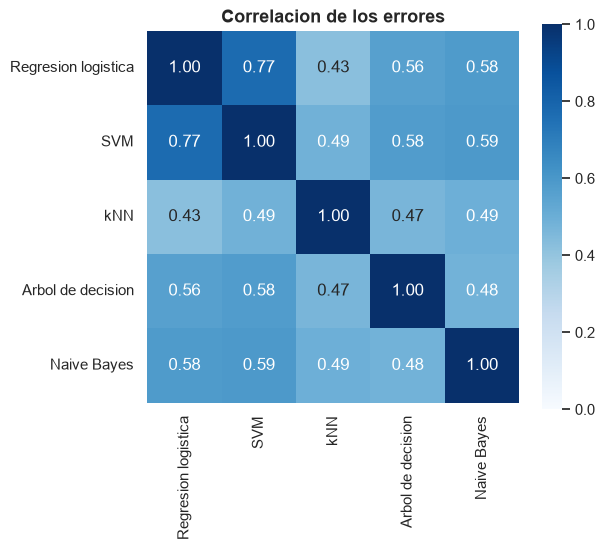

Tasa de error de cada modelo: {'Regresion logistica': 0.273, 'SVM': 0.275, 'kNN': 0.332, 'Arbol de decision': 0.285, 'Naive Bayes': 0.313}
Correlacion media entre pares: 0.544
Clase de los estudiantes en que fallan los cinco: {'dropout': 0.474, 'enrolled': 0.403, 'graduate': 0.123}


,modelos que fallan,observado,si fueran independientes
0,0,0.4860,0.1729
1,1,0.1450,0.3642
2,2,0.0924,0.3059
3,3,0.0777,0.1281
4,4,0.0791,0.0267
5,5,0.1198,0.0022


In [12]:
predicciones = pd.DataFrame({n: cross_val_predict(m, X, y, cv=PLIEGUES, n_jobs=-1) for n, m in BASE.items()}, index=y.index)
errores = predicciones.ne(y, axis=0).astype(int)
corr_errores = errores.corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr_errores, annot=True, fmt=".2f", cmap=CMAP_CONF, vmin=0, vmax=1, square=True)
plt.title("Correlacion de los errores")
mostrar("4_1_correlacion_errores")

# Distribucion si los errores fueran independientes
independiente = np.array([1.0])
for p in errores.mean():
    independiente = np.convolve(independiente, [1 - p, p])
modelos_fallan = errores.sum(axis=1)
pares = corr_errores.values[np.triu_indices(5, k=1)]

print("Tasa de error de cada modelo:", errores.mean().round(3).to_dict())
print(f"Correlacion media entre pares: {pares.mean():.3f}")
print("Clase de los estudiantes en que fallan los cinco:",
      y[modelos_fallan == 5].value_counts(normalize=True).round(3).to_dict())
pd.DataFrame({"modelos que fallan": range(6),
              "observado": modelos_fallan.value_counts(normalize=True).sort_index().values,
              "si fueran independientes": independiente})

**Qué hace el código.**

- Obtiene con `cross_val_predict` la predicción fuera de muestra de cada modelo y marca sus errores.
- Dibuja la matriz de correlación de los errores y calcula la distribución que se esperaría si los errores fueran independientes. Para eso usa la convolución de cinco variables Bernoulli, cada una con la tasa de error de su modelo.
- Muestra a qué clase pertenecen los estudiantes en los que fallan los cinco modelos.

**Lectura. ¿Qué tan correlacionados están los errores, y qué implica?** Están bastante correlacionados. La correlación media entre pares es de 0.54, y llega a 0.77 entre la regresión logística y el SVM, lo cual es esperable porque usan el mismo preprocesamiento y los mismos pesos. Si los errores fueran independientes, los cinco modelos fallarían juntos solo en el 0.2 % de los estudiantes; en realidad ocurre en el **12.0 %**, unas 55 veces más.

**¿Qué implica?** Una votación solo corrige un error cuando la mayoría acierta. Pero al menos tres de los cinco modelos fallan en el 27.7 % de los estudiantes, casi lo mismo que la tasa de error del mejor modelo individual (27.3 %). Si los errores fueran independientes, ese porcentaje sería de 15.7 %. Por eso combinar estos cinco modelos casi no gana nada.

Además, los estudiantes en los que fallan todos no son solo de la clase `enrolled` (40 %): el 47 % son `dropout`. Esto sugiere que a esos estudiantes les falta información en los atributos, y ese es un problema que ningún modelo ni ninguna combinación de modelos puede resolver.

---

## 5. Bagging optimizado: Random Forest y Extra-Trees

En la sección 2 se usó bagging con sus valores por defecto. Ahora se optimizan dos versiones mejoradas de bagging:

- **Random Forest** agrega a bagging una decisión aleatoria: en cada corte solo considera una fracción de los atributos (`max_features`). Así los árboles se parecen menos entre sí, lo que reduce la correlación ρ de la fórmula de la sección 2.1.
- **Extra-Trees** va un paso más allá y también elige al azar el punto de corte. Por defecto no usa *bootstrap*, así que se agrega como hiperparámetro.

| Hiperparámetro | Rango | Efecto |
|---|---|---|
| `max_features` | 0.05 – 0.80 | Fracción de atributos en cada corte: con menos atributos, los árboles son más distintos pero más débiles |
| `min_samples_leaf` | 1 – 29 | Tamaño mínimo de hoja: controla cuánto memoriza cada árbol |
| `max_depth` | 5, 10, 15, 20, 30, sin límite | Profundidad máxima |
| `criterion` | `gini`, `entropy` | Medida de impureza |
| `class_weight` | ninguno, `balanced`, `balanced_subsample` | Compensa el desbalance, de forma global o por muestra *bootstrap* |
| `bootstrap` (Extra-Trees) | sí, no | Si cada árbol usa una muestra *bootstrap* o todos los datos |

`n_estimators` se deja fijo en 300, ya que la curva de la sección 2 muestra que en ese punto ya está casi plana. Se usa `RandomizedSearchCV` con 60 configuraciones porque, cuando solo unos pocos hiperparámetros influyen de verdad, la búsqueda aleatoria cubre mejor el espacio que una malla (Bergstra y Bengio, 2012). Los árboles no necesitan preprocesamiento, como se vio en la sección 4.2 de la Práctica 3.

Random Forest: 60 configuraciones en 53 s
Mejor F1 macro: 0.6835 +- 0.0144
Mejor configuracion: class_weight=balanced, criterion=gini, max_depth=30, max_features=0.191, min_samples_leaf=4
Encontrada en la configuracion 44. Las cinco mejores: [0.6835, 0.681, 0.6809, 0.68, 0.6799]


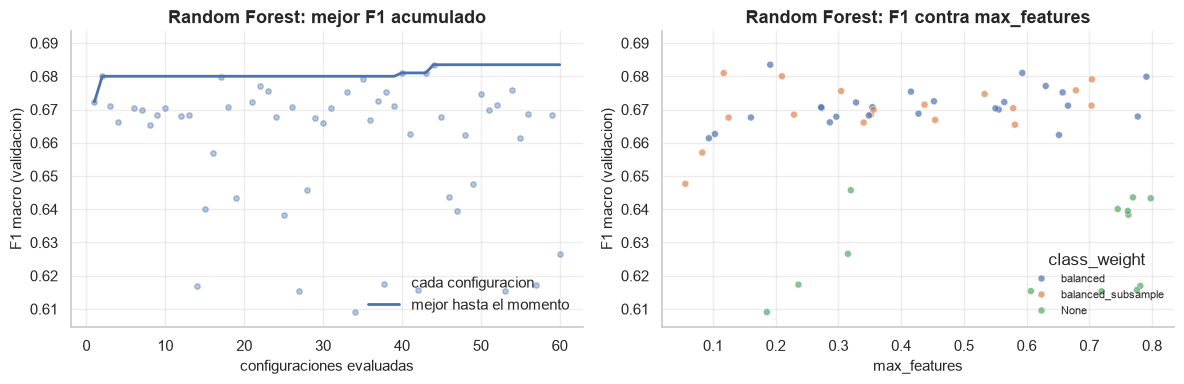

Extra-Trees: 60 configuraciones en 34 s
Mejor F1 macro: 0.6736 +- 0.0155
Mejor configuracion: bootstrap=True, class_weight=balanced, criterion=entropy, max_depth=None, max_features=0.593, min_samples_leaf=4
Encontrada en la configuracion 36. Las cinco mejores: [0.6736, 0.6704, 0.6665, 0.666, 0.6658]


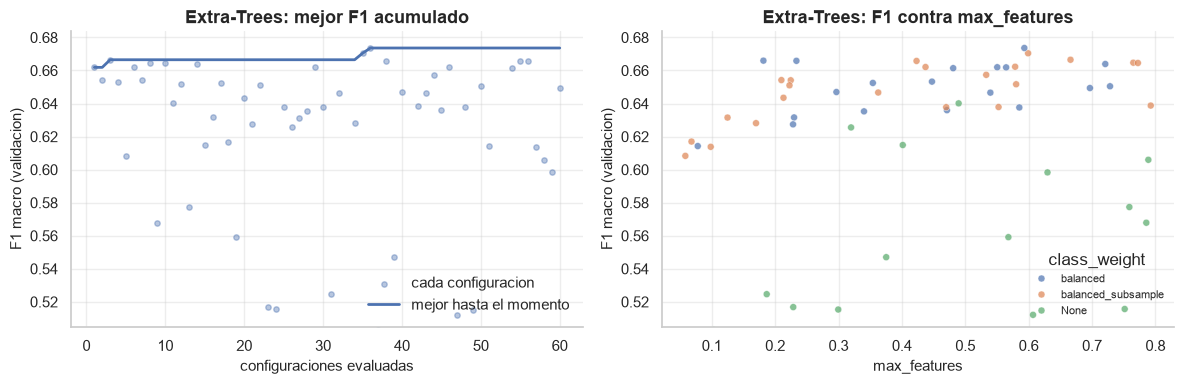

In [13]:
ESPACIO_ARBOLES = {
    "max_features": uniform(0.05, 0.75),
    "min_samples_leaf": randint(1, 30),
    "max_depth": [None, 5, 10, 15, 20, 30],
    "criterion": ["gini", "entropy"],
    "class_weight": [None, "balanced", "balanced_subsample"],
}

buscar("Random Forest", RandomForestClassifier(n_estimators=300, random_state=SEED),
       ESPACIO_ARBOLES, "Bagging optimizado", DESERCION)
grafica_meseta("Random Forest", DESERCION, "max_features", "5")

buscar("Extra-Trees", ExtraTreesClassifier(n_estimators=300, random_state=SEED),
       {**ESPACIO_ARBOLES, "bootstrap": [True, False]}, "Bagging optimizado", DESERCION)
grafica_meseta("Extra-Trees", DESERCION, "max_features", "5")

**Qué hace el código.**

- Define el espacio de búsqueda común y le agrega `bootstrap` para Extra-Trees.
- Evalúa 60 configuraciones de cada modelo con los mismos pliegues y dibuja sus gráficas de meseta, separando los puntos por `class_weight`.

**Lectura.** Random Forest llega a 0.6835 y Extra-Trees a 0.6736. Los dos eligen `class_weight="balanced"`, y en Random Forest esa es la decisión que más pesa: sin pesos, casi todas sus configuraciones quedan por debajo de 0.65. Con pesos, `max_features` casi no influye entre 0.1 y 0.8, salvo en los valores más bajos.

La gráfica de la izquierda muestra que la búsqueda se estabiliza muy pronto: Random Forest llega a 0.680 desde la segunda configuración, y las 58 siguientes solo añaden 0.0035. Es decir, se llegó a una meseta. En resumen, optimizar y compensar el desbalance sube a bagging de 0.658 a 0.684, y la sensibilidad de `enrolled` de 0.323 a 0.535.

---

## 6. Boosting optimizado: XGBoost y LightGBM

Así como la sección 5 optimizó bagging, aquí se optimiza boosting con dos bibliotecas especializadas. A diferencia de AdaBoost, estas bibliotecas ajustan cada árbol al gradiente de la pérdida, usan árboles más profundos que un tocón y regularizan el valor de cada hoja. La diferencia principal entre ambas es cómo crecen sus árboles: XGBoost los limita por profundidad, mientras que LightGBM los hace crecer por la hoja con más ganancia, así que en él se limita el número de hojas.

| Hiperparámetro | Rango | Efecto |
|---|---|---|
| `learning_rate` | 0.005 – 0.3 (log) | Cuánto aporta cada árbol |
| `n_estimators` | 100 – 799 | Número de árboles; se compensa con la tasa de aprendizaje |
| `max_depth` (XGBoost) | 2 – 9 | Profundidad de cada árbol |
| `num_leaves` (LightGBM) | 4 – 63 | Hojas de cada árbol |
| `min_child_weight` / `min_child_samples` | 0.1 – 20 (log) / 5 – 59 | Mínimo de datos en una hoja |
| `reg_lambda` | 0.001 – 100 (log) | Regularización L2 de los valores de las hojas |
| `subsample` | 0.5 – 1.0 | Fracción de filas por árbol |
| `colsample_bytree` | 0.3 – 1.0 | Fracción de columnas por árbol |
| `class_weight` | ninguno, `balanced` | Pesos por clase, aplicados con `ConPesos` |

XGBoost: 60 configuraciones en 60 s
Mejor F1 macro: 0.6991 +- 0.0234
Mejor configuracion: class_weight=balanced, colsample_bytree=0.645, learning_rate=0.024, max_depth=7, min_child_weight=0.374, n_estimators=457, reg_lambda=0.00495, subsample=0.988
Encontrada en la configuracion 7. Las cinco mejores: [0.6991, 0.6924, 0.6893, 0.6877, 0.685]


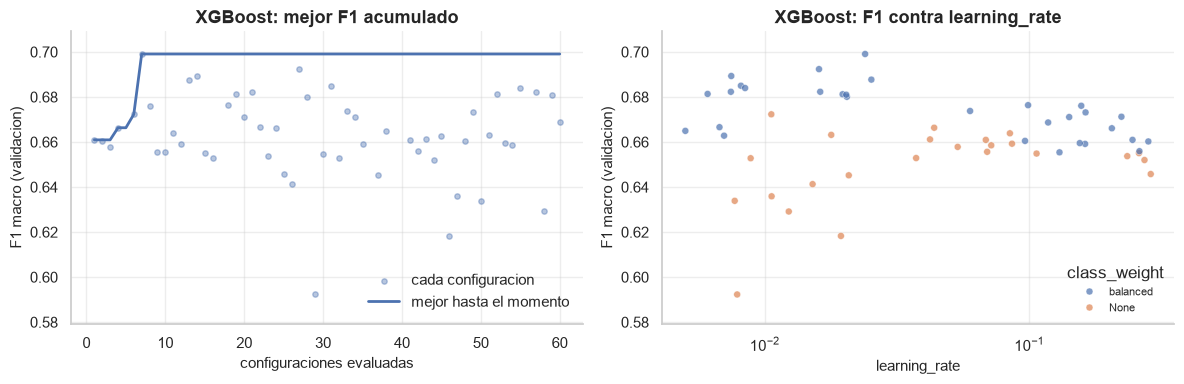

LightGBM: 60 configuraciones en 40 s
Mejor F1 macro: 0.6891 +- 0.0134
Mejor configuracion: class_weight=balanced, colsample_bytree=0.769, learning_rate=0.013, min_child_samples=57, n_estimators=640, num_leaves=12, reg_lambda=0.0629, subsample=0.928
Encontrada en la configuracion 15. Las cinco mejores: [0.6891, 0.6889, 0.6887, 0.6865, 0.6861]


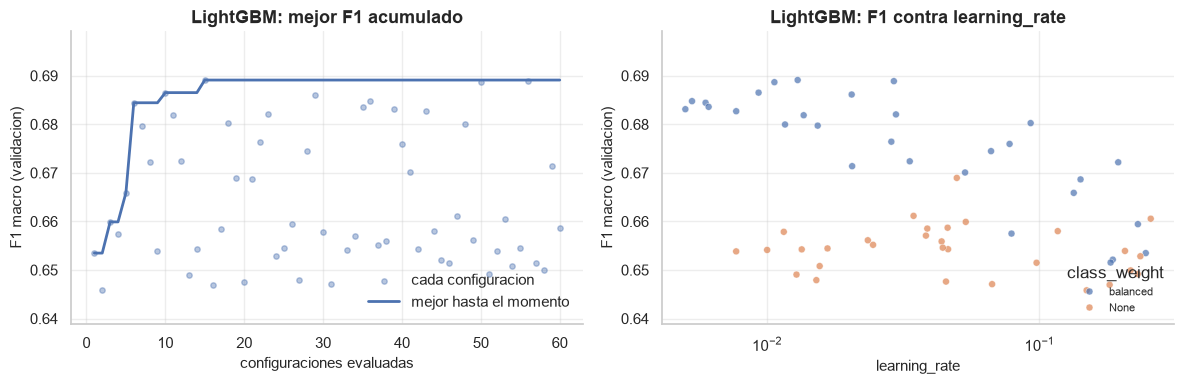

In [14]:
ESPACIO_BOOSTING = {
    "class_weight": [None, "balanced"],
    "estimador__learning_rate": loguniform(5e-3, 0.3),
    "estimador__n_estimators": randint(100, 800),
    "estimador__reg_lambda": loguniform(1e-3, 100),
    "estimador__subsample": uniform(0.5, 0.5),
    "estimador__colsample_bytree": uniform(0.3, 0.7),
}

buscar("XGBoost", ConPesos(XGBClassifier(tree_method="hist", n_jobs=1, random_state=SEED)),
       {**ESPACIO_BOOSTING, "estimador__max_depth": randint(2, 10), "estimador__min_child_weight": loguniform(0.1, 20)},
       "Boosting optimizado", DESERCION)
grafica_meseta("XGBoost", DESERCION, "estimador__learning_rate", "6", log=True)

buscar("LightGBM", ConPesos(LGBMClassifier(subsample_freq=1, n_jobs=1, random_state=SEED, verbose=-1)),
       {**ESPACIO_BOOSTING, "estimador__num_leaves": randint(4, 64), "estimador__min_child_samples": randint(5, 60)},
       "Boosting optimizado", DESERCION)
grafica_meseta("LightGBM", DESERCION, "estimador__learning_rate", "6", log=True)

**Qué hace el código.**

- Define el espacio de búsqueda común y le agrega a cada biblioteca su propio control de complejidad (profundidad en XGBoost y número de hojas en LightGBM).
- Fija `subsample_freq=1`, que es necesario para que LightGBM realmente aplique `subsample` en cada árbol.
- Evalúa 60 configuraciones de cada biblioteca y dibuja sus gráficas de meseta.

**Lectura.** XGBoost logra el mejor F1 de toda la práctica en deserción (0.6991), pero hay que tomarlo con cuidado: **ese máximo es un pico aislado**. Apareció en la configuración 7, y las siguientes mejores dan 0.6924 y 0.6893. En LightGBM, en cambio, las tres mejores están muy juntas (0.6891, 0.6889 y 0.6887), lo que da un resultado más confiable. Por eso, una estimación más prudente del boosting optimizado es ≈ 0.69.

Igual que en bagging, las dos bibliotecas eligen `balanced`, y en XGBoost las tasas de aprendizaje bajas (< 0.03) son las que dan los mejores resultados.

---

## 7. Comparación de todos los modelos

En esta sección se reúnen todos los modelos de la Parte 1 para responder la pregunta principal de la práctica. Primero se presenta la tabla general, después se compara cada modelo contra el mejor modelo base y por último se revisa la matriz de confusión del mejor.

### 7.1 Tabla general

In [15]:
tabla_des = tabla_resultados(DESERCION, "sensibilidad enrolled")
tabla_des

,modelo,familia,F1 macro (media),F1 macro (desv.),sensibilidad enrolled,tiempo (s),mejor configuracion
0,XGBoost,Boosting optimizado,0.6991,0.0234,0.4976,3.8021,"class_weight=balanced, colsample_bytree=0.645, learning_rate=0.024, max_depth=7, min_child_weight=0.374, n_estimators=457, reg_lambda=0.00495, subsample=0.988"
1,LightGBM,Boosting optimizado,0.6891,0.0134,0.5827,1.4244,"class_weight=balanced, colsample_bytree=0.769, learning_rate=0.013, min_child_samples=57, n_estimators=640, num_leaves=12, reg_lambda=0.0629, subsample=0.928"
2,Stacking (meta balanced),Combinacion,0.6872,0.0167,0.5937,13.9732,
3,Regresion logistica,Base (P3),0.6854,0.0185,0.5811,0.6416,
4,Random Forest,Bagging optimizado,0.6835,0.0144,0.5354,2.1178,"class_weight=balanced, criterion=gini, max_depth=30, max_features=0.191, min_samples_leaf=4"
5,SVM,Base (P3),0.6820,0.0216,0.5811,0.5225,
6,Votacion dura,Combinacion,0.6814,0.0193,0.4945,1.5031,
7,Extra-Trees,Bagging optimizado,0.6736,0.0155,0.5480,2.4915,"bootstrap=True, class_weight=balanced, criterion=entropy, max_depth=None, max_features=0.593, min_samples_leaf=4"
8,Votacion suave,Combinacion,0.6683,0.0196,0.3638,2.6278,
9,Stacking (meta sin pesos),Combinacion,0.6648,0.0164,0.3339,14.0820,


**Qué hace el código.**

- Reúne todos los modelos ordenados por F1 macro, con la desviación entre pliegues, la sensibilidad de `enrolled`, el tiempo de entrenamiento por pliegue y la mejor configuración de los modelos optimizados.

**Lectura.** XGBoost encabeza la tabla, seguido de LightGBM, el stacking con pesos y la regresión logística. Algo importante es que el F1 más alto no corresponde a la sensibilidad más alta: XGBoost detecta el 49.8 % de los `enrolled`, contra el 58.1 % de la regresión logística.

El costo también cambia mucho entre modelos. El stacking tarda ≈ 17 s por pliegue, contra ≈ 0.6 s de la logística, y todo eso para ganar apenas 0.002 de F1.

### 7.2 ¿Cuánto ganan los ensambles?

Comparar solo las medias de la tabla puede engañar, porque la variación entre pliegues es del mismo orden que las diferencias entre modelos. Como todos los modelos usan los mismos pliegues, se pueden comparar **por pares**: se calcula la diferencia de F1 pliegue a pliegue contra el mejor modelo base. Si la diferencia media es menor que su variación entre pliegues, no hay evidencia sólida de que el ensamble realmente sea mejor.

In [16]:
mejor_base = tabla_des[tabla_des["familia"] == "Base (P3)"].iloc[0]["modelo"]
f1_ref = DESERCION["tabla"][mejor_base]["f1"]

filas = []
for nombre in tabla_des["modelo"]:
    if nombre != mejor_base:
        dif = DESERCION["tabla"][nombre]["f1"] - f1_ref
        filas.append([nombre, dif.mean(), dif.std(), (dif > 0).sum()])
print("Referencia:", mejor_base)
pd.DataFrame(filas, columns=["modelo", "ganancia media", "desv. de la diferencia", "pliegues ganados (de 5)"]).head(6)

Referencia: Regresion logistica


,modelo,ganancia media,desv. de la diferencia,pliegues ganados (de 5)
0,XGBoost,0.0136,0.0118,4
1,LightGBM,0.0037,0.0172,2
2,Stacking (meta balanced),0.0018,0.0027,3
3,Random Forest,-0.0020,0.0111,3
4,SVM,-0.0034,0.0110,3
5,Votacion dura,-0.0041,0.0017,0


**Qué hace el código.**

- Identifica el mejor modelo base y calcula, pliegue a pliegue, la diferencia de F1 de los demás modelos contra él, junto con el número de pliegues en que cada uno gana.

**Lectura. ¿Cuánto ganan los ensambles?** Poco. El mejor ensamble gana **+0.014 ± 0.012** contra la regresión logística, y gana en 4 de los 5 pliegues. Sin embargo, la diferencia apenas supera su variación entre pliegues, y además es el máximo de 60 configuraciones, así que está sesgada hacia arriba. LightGBM (+0.004) y el stacking (+0.002) no se distinguen de la logística, y la votación dura pierde en los 5 pliegues.

Donde los ensambles sí ganan mucho es contra sus propios modelos **débiles**: +0.069 sobre el árbol sin límite y +0.139 sobre el tocón. La conclusión es que los ensambles son muy útiles para mejorar modelos débiles, pero cuando los modelos base ya están bien ajustados queda poco por ganar.

### 7.3 Matriz de confusión del mejor modelo

Se revisa en qué clases acierta y en cuáles se equivoca el mejor modelo, para saber de dónde viene su ventaja.

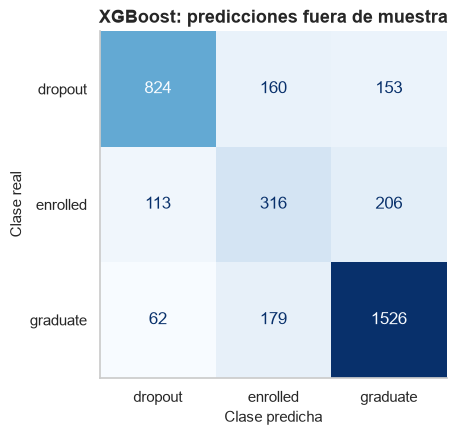

              precision    recall  f1-score   support

     dropout      0.825     0.725     0.772      1137
    enrolled      0.482     0.498     0.490       635
    graduate      0.810     0.864     0.836      1767

    accuracy                          0.753      3539
   macro avg      0.706     0.695     0.699      3539
weighted avg      0.756     0.753     0.753      3539



In [17]:
mejor_des = tabla_des.iloc[0]["modelo"]
modelo_des = DESERCION["tabla"][mejor_des]["estimador"]
pred_des = cross_val_predict(modelo_des, X, y, cv=PLIEGUES, n_jobs=-1)

ConfusionMatrixDisplay.from_predictions(y, pred_des, labels=CLASES, cmap=CMAP_CONF, colorbar=False)
plt.grid(False)
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.title(f"{mejor_des}: predicciones fuera de muestra")
mostrar("7_3_matriz_confusion_desercion")

print(classification_report(y, pred_des, labels=CLASES, digits=3))

**Qué hace el código.**

- Toma el primer modelo de la tabla, obtiene sus predicciones fuera de muestra y dibuja su matriz de confusión junto con su reporte por clase.

**Lectura.** XGBoost no resuelve el problema de `enrolled`: su F1 en esa clase es 0.490, prácticamente el mismo que en la Práctica 3 (0.489 con la logística). Lo que gana viene de las otras dos clases, con un F1 de `dropout` de 0.772 contra 0.751 y de `graduate` de 0.836 contra 0.816. La confusión sigue concentrada en `enrolled`, lo cual tiene sentido porque es una clase intermedia entre las otras dos: un estudiante que sigue inscrito puede parecerse tanto a uno que se gradúa como a uno que deserta.

---

## 8. Bank Marketing

En esta segunda parte se busca el mejor modelo para otro conjunto de datos, usando todo lo visto hasta ahora: preprocesamiento, balanceo de clases, clasificadores, optimización y ensambles. Además, se revisa si lo que funcionó en deserción también funciona aquí.

### 8.1 Datos

Se usa `bank-additional-full.csv` sin la columna `duration`, ya que la duración de la llamada solo se conoce al terminarla y no se puede usar para decidir a quién llamar (Tarea 4). La evaluación se hace con `StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)`, como pide el enunciado.

Comparado con deserción, este conjunto tiene tres diferencias importantes:

- **Es binario y mucho más desbalanceado:** solo el 11.3 % de las llamadas terminan en `yes`, contra el 17.9 % de la clase más pequeña en deserción.
- **Es 12 veces más grande**, así que el tiempo de entrenamiento de algunos modelos se vuelve un problema real.
- **`pdays = 999` significa "nunca contactado"**, no una cantidad de días. Dentro del pipeline, `SimpleImputer(missing_values=999, add_indicator=True)` cambia el 999 por 0 y agrega el indicador `nunca_contactado`.

Como pide el enunciado, `X` es el archivo sin `duration` ni `y`, y `y` vale 1 (`yes`) o 0 (`no`). Todo lo que se ajusta con datos (codificación, escalado, remuestreo y umbral) va dentro del modelo, de modo que solo aprende de los pliegues de entrenamiento y nunca del pliegue de validación.

In [18]:
SEED_BANCO = 2026

banco = pd.read_csv(CARPETA_DATOS / "Bank Marketing" / "bank-additional-full.csv", sep=";").drop(columns="duration")
y_banco = (banco.pop("y") == "yes").astype(int)
X_banco = banco

CATEGORICOS_B = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "day_of_week", "poutcome"]
NUMERICOS_B = [c for c in X_banco.columns if c not in CATEGORICOS_B]

CV_BANCO = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED_BANCO)
CV_INTERNO_B = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED_BANCO)

ESCORES_B = {"f1": "f1_macro", "sens": make_scorer(recall_score, labels=[1], average="macro", zero_division=0)}
BANCO = {"nombre": "banco", "X": X_banco, "y": y_banco, "pliegues": CV_BANCO, "escores": ESCORES_B, "seed": SEED_BANCO, "tabla": {}}

def pdays_indicador():
    """pdays = 999 pasa a 0 y se agrega el indicador nunca_contactado al final de los numericos"""
    return SimpleImputer(missing_values=999, strategy="constant", fill_value=0, add_indicator=True)

def prep_onehot(indicador=True):
    """One-hot y escalado para modelos lineales, SVM, kNN y SMOTE"""
    numericos = Pipeline([("pdays", pdays_indicador()), ("escala", StandardScaler())]) if indicador else StandardScaler()
    return ColumnTransformer([
        ("categoricos", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICOS_B),
        ("numericos", numericos, NUMERICOS_B),
    ])

def prep_ordinal():
    """Codigos enteros para arboles; de los numericos solo cambia pdays"""
    return ColumnTransformer([
        ("categoricos", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CATEGORICOS_B),
        ("numericos", pdays_indicador(), NUMERICOS_B),
    ])

print("Llamadas:", X_banco.shape[0], " Atributos:", X_banco.shape[1])
print(f"Proporcion de yes: {y_banco.mean():.4f}")
print(f"pdays = 999: {(X_banco['pdays'] == 999).mean():.4f}")
print("Otros numericos con 999:", [c for c in NUMERICOS_B if c != "pdays" and (X_banco[c] == 999).any()])
print("Valores 'unknown':", (X_banco == "unknown").sum()[lambda s: s > 0].to_dict())
print("Filas repetidas (atributos y clase):", pd.concat([X_banco, y_banco], axis=1).duplicated().sum())


Llamadas: 41188  Atributos: 19
Proporcion de yes: 0.1127
pdays = 999: 0.9632
Otros numericos con 999: []
Valores 'unknown': {'job': 330, 'marital': 80, 'education': 1731, 'default': 8597, 'housing': 990, 'loan': 990}
Filas repetidas (atributos y clase): 1784


**Qué hace el código.**

- Quita `duration` y codifica `yes = 1` y `no = 0`. `X_banco` queda igual al archivo original, sin `duration` ni `y`.
- Define los pliegues con la semilla 2026 y la sensibilidad de `yes`. `BANCO` guarda el propio `StratifiedKFold`, así que cada `cross_validate` y cada búsqueda reciben exactamente el objeto que pide el enunciado.
- Define `pdays_indicador`, que trata el 999 dentro del pipeline. Antes se comprueba que ningún otro atributo numérico tiene el valor 999, para que solo `pdays` reciba indicador.
- Trata `unknown` como una categoría más, como permite la ficha del dataset.
- Conserva las filas repetidas, porque el enunciado pide usar las 41 188 instancias.

**Lectura.** `pdays = 999` aparece en el 96.3 % de las llamadas, es decir, casi ningún cliente había sido contactado antes. El valor `unknown` pesa sobre todo en `default` (8597 llamadas, 20.9 %). También hay 1784 filas repetidas una vez que se quita `duration`. Estas filas pueden caer al mismo tiempo en entrenamiento y en validación, lo que favorece un poco a los modelos que memorizan.

---

### 8.2 ¿Sirve directamente el mejor modelo de deserción?

Antes de optimizar nada, se prueba qué tan bien funciona el mejor modelo de la sección 7 si se aplica tal cual, con sus mismos hiperparámetros. También se evalúa una referencia que siempre predice `no`, para tener claro cuál es el piso.

In [19]:
evaluar("Referencia: siempre no", DummyClassifier(strategy="most_frequent"), "Referencia", BANCO)
evaluar(f"{mejor_des} (config. de desercion)", Pipeline([("prep", prep_ordinal()), ("modelo", clone(modelo_des))]),
        "Transferido", BANCO, config=DESERCION["tabla"][mejor_des]["config"])

Referencia: siempre no                 F1 = 0.4702 +- 0.0000   sens = 0.000   tiempo = 0.01 s
XGBoost (config. de desercion)         F1 = 0.6944 +- 0.0047   sens = 0.602   tiempo = 1.95 s


**Qué hace el código.**

- Evalúa la referencia y el mejor modelo de deserción sin volver a buscar sus hiperparámetros. Las variables categóricas se convierten en códigos enteros, que es lo que necesitan los árboles.

**Lectura.** Predecir siempre `no` da un 88.7 % de exactitud, lo que a primera vista parece muy bueno. Pero su F1 macro es de 0.470 y su sensibilidad de 0, porque nunca encuentra a un cliente que acepte. Por eso la exactitud no sirve como métrica en este problema.

El modelo transferido logra 0.694, que es un buen punto de partida. Sin embargo, en la sección 8.5 se verá que queda 0.024 por debajo del mismo XGBoost cuando se vuelven a optimizar sus hiperparámetros para este conjunto.

---

### 8.3 Preprocesamiento y balanceo

Como el desbalance es mucho más fuerte que en deserción, primero se compara cómo manejarlo. Se prueban cinco estrategias sobre un modelo lineal (regresión logística) y uno de boosting (LightGBM). Todas se aplican dentro de cada pliegue:

| Estrategia | Qué hace |
|---|---|
| Sin balanceo | Usa el umbral de 0.5 y da el mismo peso a todos los datos |
| `class_weight="balanced"` | Da más peso a cada `yes` (≈ 7.9 veces el de un `no`) |
| SMOTE | Crea `yes` sintéticos interpolando entre vecinos, solo en el entrenamiento |
| Submuestreo | Descarta `no` al azar hasta igualar las clases |
| Umbral optimizado | Entrena sin pesos y elige el umbral que maximiza el F1 macro (`TunedThresholdClassifierCV`) con una validación interna |

SMOTE usa one-hot y escalado en los dos modelos, porque interpola usando distancias. La desventaja es que con one-hot también interpola las categorías, lo que produce valores intermedios sin significado; es una limitación conocida de esta versión de SMOTE.

Además, se mide si ayudan dos decisiones de preprocesamiento: el indicador de `pdays` y usar one-hot en lugar de códigos enteros en LightGBM.

In [20]:
def logistica_b(**kw):
    return LogisticRegression(max_iter=1000, random_state=SEED_BANCO, **kw)

def lightgbm_b(**kw):
    return ConPesos(LGBMClassifier(n_jobs=1, random_state=SEED_BANCO, verbose=-1), **kw)

MODELOS_BAL = {"LR": (logistica_b, prep_onehot), "LightGBM": (lightgbm_b, prep_ordinal)}

for nombre, (fabrica, prep) in MODELOS_BAL.items():
    evaluar(f"{nombre}: sin balanceo", Pipeline([("prep", prep()), ("modelo", fabrica())]), "Balanceo", BANCO)
    evaluar(f"{nombre}: class_weight", Pipeline([("prep", prep()), ("modelo", fabrica(class_weight="balanced"))]), "Balanceo", BANCO)
    evaluar(f"{nombre}: SMOTE", PipelineImb([("prep", prep_onehot()), ("balanceo", SMOTE(random_state=SEED_BANCO)),
                                             ("modelo", fabrica())]), "Balanceo", BANCO)
    evaluar(f"{nombre}: submuestreo", PipelineImb([("prep", prep()), ("balanceo", RandomUnderSampler(random_state=SEED_BANCO)),
                                                   ("modelo", fabrica())]), "Balanceo", BANCO)
    evaluar(f"{nombre}: umbral optimizado", TunedThresholdClassifierCV(
        Pipeline([("prep", prep()), ("modelo", fabrica())]), scoring="f1_macro", cv=CV_INTERNO_B), "Balanceo", BANCO)

evaluar("LR: class_weight, pdays sin indicador", Pipeline([("prep", prep_onehot(indicador=False)),
        ("modelo", logistica_b(class_weight="balanced"))]), "Preprocesamiento", BANCO)
evaluar("LightGBM: class_weight, one-hot", Pipeline([("prep", prep_onehot()), ("modelo", lightgbm_b(class_weight="balanced"))]),
        "Preprocesamiento", BANCO)

LR: sin balanceo                       F1 = 0.6424 +- 0.0096   sens = 0.229   tiempo = 0.61 s
LR: class_weight                       F1 = 0.6741 +- 0.0043   sens = 0.628   tiempo = 0.79 s
LR: SMOTE                              F1 = 0.6675 +- 0.0046   sens = 0.632   tiempo = 1.64 s
LR: submuestreo                        F1 = 0.6735 +- 0.0055   sens = 0.633   tiempo = 0.25 s
LR: umbral optimizado                  F1 = 0.7080 +- 0.0055   sens = 0.523   tiempo = 2.76 s
LightGBM: sin balanceo                 F1 = 0.6644 +- 0.0085   sens = 0.272   tiempo = 0.30 s
LightGBM: class_weight                 F1 = 0.6903 +- 0.0047   sens = 0.633   tiempo = 0.30 s
LightGBM: SMOTE                        F1 = 0.6816 +- 0.0127   sens = 0.328   tiempo = 1.50 s
LightGBM: submuestreo                  F1 = 0.6742 +- 0.0066   sens = 0.645   tiempo = 0.17 s
LightGBM: umbral optimizado            F1 = 0.7181 +- 0.0068   sens = 0.534   tiempo = 2.00 s
LR: class_weight, pdays sin indicador  F1 = 0.6739 +- 0.0040

**Qué hace el código.**

- Evalúa las cinco estrategias sobre la regresión logística y LightGBM, con hiperparámetros por defecto. `PipelineImb`, de imbalanced-learn, aplica el remuestreo solo al ajustar el modelo y nunca al predecir.
- Evalúa dos variantes de preprocesamiento: la logística sin el indicador de `pdays` y LightGBM con one-hot.

**Lectura.** La primera conclusión es que **balancear importa mucho más que el preprocesamiento**. El indicador de `pdays` cambia el F1 en 0.0002 y el one-hot en LightGBM en 0.0012, mientras que cambiar la estrategia de balanceo mueve el F1 hasta 0.066 en la logística.

Entre las estrategias, **el umbral gana con claridad**. En la logística, el F1 pasa de 0.642 sin balanceo a 0.674 con `class_weight`, y a **0.708** con el umbral optimizado. En LightGBM pasa de 0.664 a 0.690 y a **0.718**. `balanced` detecta más `yes` (0.63 contra 0.53), pero lo hace con demasiadas falsas alarmas, y el F1 macro lo castiga.

Por último, **remuestrear no ayuda**: el submuestreo queda igual o peor que `class_weight`, y SMOTE también queda por debajo (0.667 y 0.682).

---

### 8.4 Clasificadores base y ensambles sin optimizar

Ahora se evalúan los demás clasificadores base de la Práctica 3 y los experimentos de las secciones 2 y 3 (árbol sin límite, bagging, tocón y AdaBoost), para tener el mismo punto de comparación que en deserción. Se usan los hiperparámetros de la Práctica 3 y se agrega un peso por clase donde el modelo lo admite.

Hay que tomar en cuenta que el SVM con kernel RBF escala mal con el número de datos, así que aquí es, con diferencia, el modelo más lento.

In [21]:
n_categorias = [banco[c].nunique() for c in CATEGORICOS_B]
arbol_libre_b = DecisionTreeClassifier(random_state=SEED_BANCO)

evaluar("Arbol (P3, balanced)", Pipeline([("prep", prep_ordinal()), ("modelo", DecisionTreeClassifier(
    max_depth=20, min_samples_leaf=19, ccp_alpha=0.0049299250581314345, class_weight="balanced", random_state=SEED_BANCO))]),
    "Base", BANCO)
evaluar("kNN (P3)", Pipeline([("prep", prep_onehot()), ("modelo", KNeighborsClassifier(n_neighbors=7, p=1))]), "Base", BANCO)
evaluar("Naive Bayes (P3)", Pipeline([
    ("prep", ColumnTransformer([("categoricos", OrdinalEncoder(), CATEGORICOS_B),
                                ("numericos", Pipeline([("pdays", pdays_indicador()),
                                                          ("intervalos", KBinsDiscretizer(12, encode="ordinal", strategy="quantile"))]),
                                 NUMERICOS_B)])),
    ("modelo", CategoricalNB(alpha=0.4448636561609948, min_categories=n_categorias + [12] * (len(NUMERICOS_B) + 1)))]), "Base", BANCO)
evaluar("SVM (P3)", Pipeline([("prep", prep_onehot()), ("modelo", SVC(
    kernel="rbf", C=1.614029086528123, gamma=0.02556814549636102, class_weight="balanced",
    cache_size=2000, random_state=SEED_BANCO))]), "Base", BANCO)
evaluar("Arbol sin limite", Pipeline([("prep", prep_ordinal()), ("modelo", arbol_libre_b)]), "Varianza", BANCO)
evaluar("Bagging (100 arboles)", Pipeline([("prep", prep_ordinal()), ("modelo", BaggingClassifier(
    arbol_libre_b, n_estimators=100, random_state=SEED_BANCO))]), "Varianza", BANCO)
tocon_b = DecisionTreeClassifier(max_depth=1, random_state=SEED_BANCO)
evaluar("Tocon", Pipeline([("prep", prep_ordinal()), ("modelo", tocon_b)]), "Sesgo", BANCO)
evaluar("AdaBoost (400 tocones)", Pipeline([("prep", prep_ordinal()), ("modelo", AdaBoostClassifier(
    tocon_b, n_estimators=400, random_state=SEED_BANCO))]), "Sesgo", BANCO)

Arbol (P3, balanced)                   F1 = 0.6765 +- 0.0064   sens = 0.598   tiempo = 0.20 s
kNN (P3)                               F1 = 0.6591 +- 0.0094   sens = 0.286   tiempo = 0.10 s
Naive Bayes (P3)                       F1 = 0.6754 +- 0.0062   sens = 0.630   tiempo = 0.10 s
SVM (P3)                               F1 = 0.6969 +- 0.0060   sens = 0.609   tiempo = 164.50 s
Arbol sin limite                       F1 = 0.6180 +- 0.0104   sens = 0.345   tiempo = 0.35 s
Bagging (100 arboles)                  F1 = 0.6670 +- 0.0064   sens = 0.311   tiempo = 11.74 s
Tocon                                  F1 = 0.4702 +- 0.0000   sens = 0.000   tiempo = 0.14 s
AdaBoost (400 tocones)                 F1 = 0.6251 +- 0.0110   sens = 0.195   tiempo = 10.75 s


**Qué hace el código.**

- Evalúa los modelos base que faltan, cada uno con el preprocesamiento de su familia. La regresión logística ya se evaluó en la sección 8.3.
- Evalúa el árbol sin límite, bagging, el tocón y AdaBoost, para comparar con lo que pasó en las secciones 2 y 3.

**Lectura.** Los mismos mecanismos de deserción vuelven a aparecer. Bagging mejora al árbol sin límite (0.618 → 0.667) sin mejorar la sensibilidad (0.345 → 0.311), y AdaBoost mejora al tocón (0.470 → 0.625).

Algo curioso es que el tocón da exactamente lo mismo que predecir siempre `no`. Esto se debe a que, con tan pocos `yes`, ningún corte logra que alguna de sus dos hojas tenga mayoría de `yes`.

El costo del SVM se dispara: con 12 veces más datos tarda unas 325 veces más (de 0.5 s a 143 s por pliegue), y aun así queda por debajo de la logística con umbral.

---

### 8.5 Optimización

Se repiten las búsquedas de deserción para Random Forest, Extra-Trees, XGBoost y LightGBM, pero con dos cambios basados en lo que se observó en las secciones anteriores:

| Cambio | Por qué |
|---|---|
| **Pesos intermedios:** además de `balanced`, se prueban pesos de 2 a 5 para `yes` | Si el umbral importa tanto como sugiere la sección 8.3, el peso óptimo podría estar por debajo de `balanced` (≈ 7.9) |
| **Hojas más grandes** | Con 12 veces más datos, cada hoja puede tener más llamadas sin perder detalle |

Random Forest y Extra-Trees usan 200 árboles y 50 configuraciones; XGBoost y LightGBM usan 60 configuraciones.

Random Forest: 50 configuraciones en 187 s
Mejor F1 macro: 0.7198 +- 0.0053
Mejor configuracion: class_weight={0: 1, 1: 3}, criterion=entropy, max_depth=12, max_features=0.531, min_samples_leaf=10
Encontrada en la configuracion 47. Las cinco mejores: [0.7198, 0.7187, 0.7172, 0.7172, 0.7166]


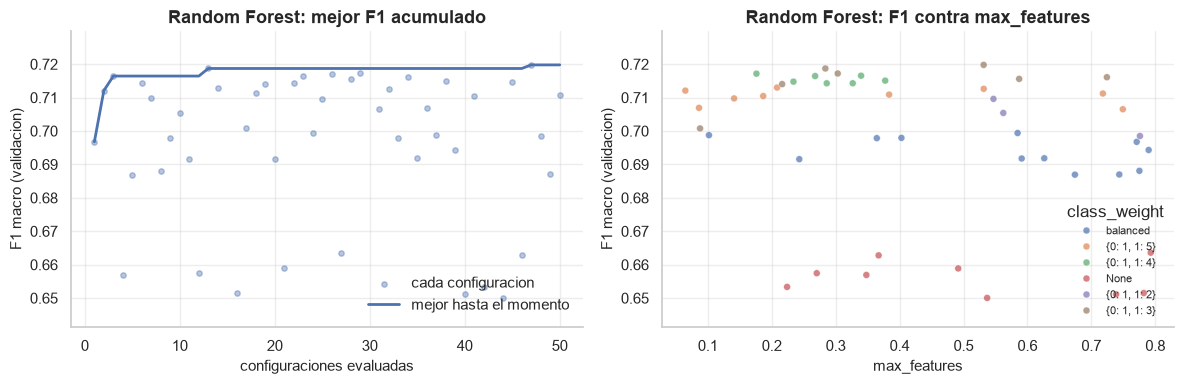

Extra-Trees: 50 configuraciones en 171 s
Mejor F1 macro: 0.7167 +- 0.0068
Mejor configuracion: bootstrap=True, class_weight={0: 1, 1: 4}, criterion=gini, max_depth=16, max_features=0.637, min_samples_leaf=8
Encontrada en la configuracion 2. Las cinco mejores: [0.7167, 0.7152, 0.714, 0.7139, 0.7138]


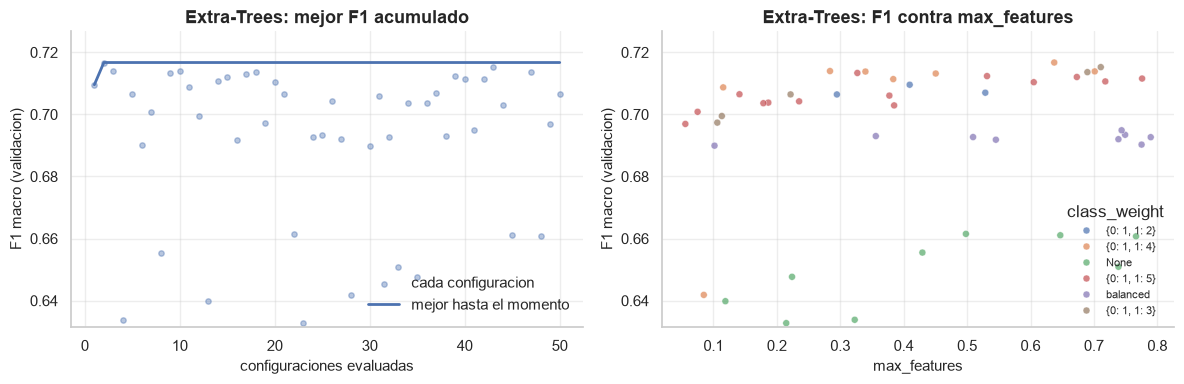

XGBoost: 60 configuraciones en 72 s
Mejor F1 macro: 0.7187 +- 0.0062
Mejor configuracion: class_weight={0: 1, 1: 3}, colsample_bytree=0.938, learning_rate=0.00996, max_depth=8, min_child_weight=11.3, n_estimators=608, reg_lambda=0.0699, subsample=0.752
Encontrada en la configuracion 11. Las cinco mejores: [0.7187, 0.7186, 0.7183, 0.7179, 0.7171]


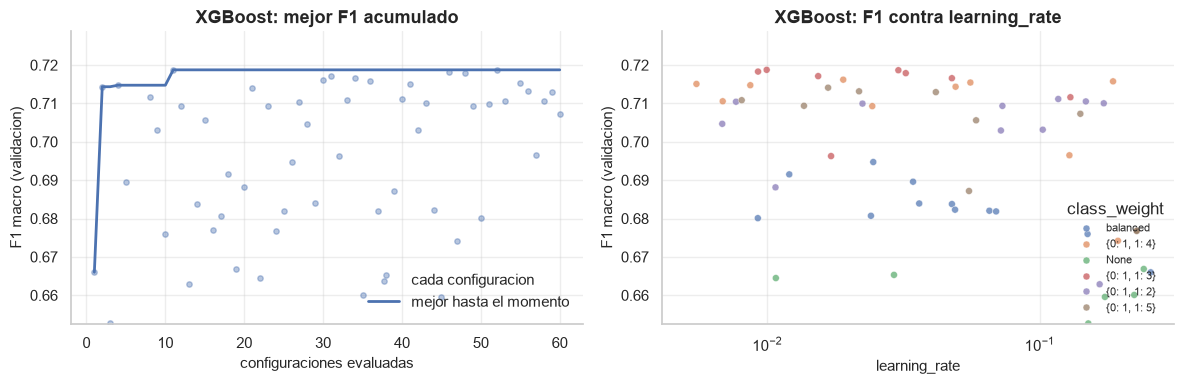

LightGBM: 60 configuraciones en 78 s
Mejor F1 macro: 0.7200 +- 0.0061
Mejor configuracion: class_weight={0: 1, 1: 3}, colsample_bytree=0.66, learning_rate=0.0169, min_child_samples=17, n_estimators=501, num_leaves=41, reg_lambda=0.0367, subsample=0.81
Encontrada en la configuracion 44. Las cinco mejores: [0.72, 0.7194, 0.7183, 0.7164, 0.7159]


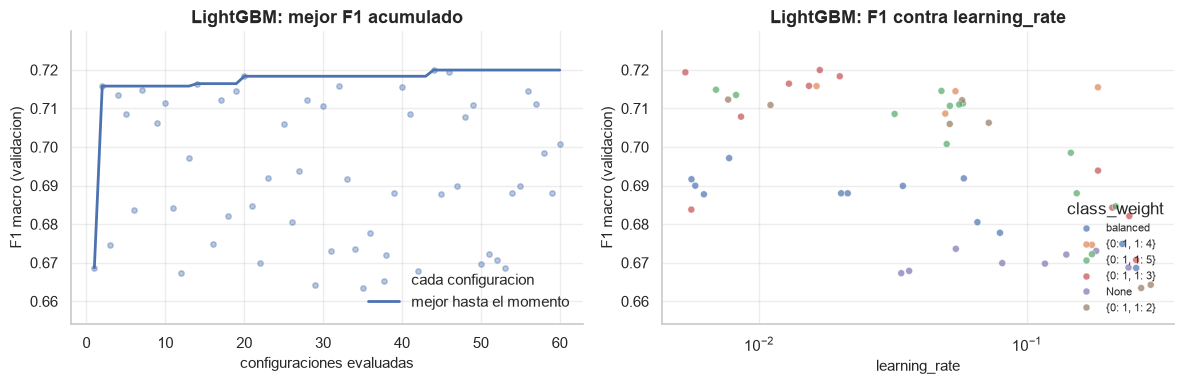

In [22]:
PESOS_B = [None, "balanced", {0: 1, 1: 2}, {0: 1, 1: 3}, {0: 1, 1: 4}, {0: 1, 1: 5}]

ESPACIO_ARBOLES_B = {
    "modelo__min_samples_leaf": randint(1, 60),
    "modelo__max_depth": [None, 8, 12, 16, 24],
    "modelo__criterion": ["gini", "entropy"],
    "modelo__max_features": uniform(0.05, 0.75),
    "modelo__class_weight": PESOS_B,
}
ESPACIO_BOOSTING_B = {
    "modelo__class_weight": PESOS_B,
    "modelo__estimador__learning_rate": loguniform(5e-3, 0.3),
    "modelo__estimador__n_estimators": randint(100, 800),
    "modelo__estimador__reg_lambda": loguniform(1e-3, 100),
    "modelo__estimador__subsample": uniform(0.5, 0.5),
    "modelo__estimador__colsample_bytree": uniform(0.3, 0.7),
}

buscar("Random Forest", Pipeline([("prep", prep_ordinal()), ("modelo", RandomForestClassifier(n_estimators=200, random_state=SEED_BANCO))]),
       ESPACIO_ARBOLES_B, "Bagging optimizado", BANCO, n_iter=50)
grafica_meseta("Random Forest", BANCO, "modelo__max_features", "8_5", separar_por="modelo__class_weight")

buscar("Extra-Trees", Pipeline([("prep", prep_ordinal()), ("modelo", ExtraTreesClassifier(n_estimators=200, random_state=SEED_BANCO))]),
       {**ESPACIO_ARBOLES_B, "modelo__bootstrap": [True, False]}, "Bagging optimizado", BANCO, n_iter=50)
grafica_meseta("Extra-Trees", BANCO, "modelo__max_features", "8_5", separar_por="modelo__class_weight")

buscar("XGBoost", Pipeline([("prep", prep_ordinal()), ("modelo", ConPesos(XGBClassifier(tree_method="hist", n_jobs=1, random_state=SEED_BANCO)))]),
       {**ESPACIO_BOOSTING_B, "modelo__estimador__max_depth": randint(2, 10), "modelo__estimador__min_child_weight": loguniform(0.1, 50)},
       "Boosting optimizado", BANCO)
grafica_meseta("XGBoost", BANCO, "modelo__estimador__learning_rate", "8_5", separar_por="modelo__class_weight", log=True)

buscar("LightGBM", Pipeline([("prep", prep_ordinal()), ("modelo", ConPesos(LGBMClassifier(subsample_freq=1, n_jobs=1, random_state=SEED_BANCO, verbose=-1)))]),
       {**ESPACIO_BOOSTING_B, "modelo__estimador__num_leaves": randint(4, 128), "modelo__estimador__min_child_samples": randint(5, 200)},
       "Boosting optimizado", BANCO)
grafica_meseta("LightGBM", BANCO, "modelo__estimador__learning_rate", "8_5", separar_por="modelo__class_weight", log=True)

**Qué hace el código.**

- Busca cada modelo dentro de un pipeline; por eso los nombres de los hiperparámetros llevan el prefijo `modelo__`.
- Dibuja la meseta de cada búsqueda, con los puntos separados por el peso de la clase.

**Lectura.** La gráfica de Random Forest separa con claridad **tres bandas según el peso de `yes`**: sin pesos el F1 queda en ≈ 0.65–0.66, con `balanced` en ≈ 0.69–0.70 y con pesos de 3 a 5 en ≈ 0.71–0.72. Los tres modelos con mejor F1 eligen un peso de **1:3**, muy por debajo del 7.9 que usa `balanced`, y Extra-Trees elige 1:4. Esto confirma lo que sugería la sección 8.3: aquí conviene compensar el desbalance, pero no por completo.

Los cuatro modelos terminan entre 0.717 y 0.720, y en cada uno las cinco mejores configuraciones quedan a 0.004 o menos de la mejor. Es decir, las búsquedas llegaron a una meseta.

---

### 8.6 Combinaciones y umbral sobre los modelos optimizados

En esta sección se intenta ganar un poco más sobre los modelos optimizados. Se combinan la regresión logística y los tres mejores modelos optimizados; los demás modelos base no se incluyen porque quedaron lejos o son muy lentos. Además se prueban tres ideas:

- Ajustar el umbral después de la búsqueda.
- Combinar los tres modelos de árboles con votación suave y después ajustar el umbral.
- Usar Random Forest con más árboles.

In [23]:
rf_opt = BANCO["tabla"]["Random Forest"]["estimador"]
xgb_opt = BANCO["tabla"]["XGBoost"]["estimador"]
lgbm_opt = BANCO["tabla"]["LightGBM"]["estimador"]
lr_b = Pipeline([("prep", prep_onehot()), ("modelo", logistica_b(class_weight="balanced"))])

ESTIMADORES_B = [("logistica", lr_b), ("rf", rf_opt), ("xgb", xgb_opt), ("lgbm", lgbm_opt)]

evaluar("Votacion dura", VotingClassifier(ESTIMADORES_B, voting="hard"), "Combinacion", BANCO)
evaluar("Votacion suave", VotingClassifier(ESTIMADORES_B, voting="soft"), "Combinacion", BANCO)
evaluar("Stacking (meta con pesos 1:3)", StackingClassifier(
    ESTIMADORES_B, final_estimator=logistica_b(class_weight={0: 1, 1: 3}), cv=CV_INTERNO_B), "Combinacion", BANCO)

for nombre, modelo in [("Random Forest", rf_opt), ("XGBoost", xgb_opt), ("LightGBM", lgbm_opt)]:
    evaluar(f"{nombre} + umbral", TunedThresholdClassifierCV(modelo, scoring="f1_macro", cv=CV_INTERNO_B),
            "Umbral", BANCO, config=BANCO["tabla"][nombre]["config"])

TRES_B = [("rf", rf_opt), ("xgb", xgb_opt), ("lgbm", lgbm_opt)]
evaluar("Votacion suave RF+XGB+LGBM + umbral", TunedThresholdClassifierCV(
    VotingClassifier(TRES_B, voting="soft"), scoring="f1_macro", cv=CV_INTERNO_B), "Umbral", BANCO)
evaluar("Random Forest (500 arboles)", clone(rf_opt).set_params(modelo__n_estimators=500), "Bagging optimizado", BANCO,
        config=BANCO["tabla"]["Random Forest"]["config"] + ", n_estimators=500")

Votacion dura                          F1 = 0.7190 +- 0.0062   sens = 0.529   tiempo = 14.59 s
Votacion suave                         F1 = 0.7181 +- 0.0060   sens = 0.566   tiempo = 14.66 s
Stacking (meta con pesos 1:3)          F1 = 0.7192 +- 0.0066   sens = 0.555   tiempo = 46.39 s
Random Forest + umbral                 F1 = 0.7185 +- 0.0060   sens = 0.530   tiempo = 28.23 s
XGBoost + umbral                       F1 = 0.7188 +- 0.0059   sens = 0.524   tiempo = 12.45 s
LightGBM + umbral                      F1 = 0.7193 +- 0.0066   sens = 0.546   tiempo = 8.17 s
Votacion suave RF+XGB+LGBM + umbral    F1 = 0.7196 +- 0.0068   sens = 0.536   tiempo = 46.30 s
Random Forest (500 arboles)            F1 = 0.7195 +- 0.0054   sens = 0.536   tiempo = 22.18 s


**Qué hace el código.**

- Reconstruye los modelos optimizados y los combina con votación dura, votación suave y stacking.
- Ajusta el umbral de cada modelo optimizado con validación interna, para ver si queda algo por ganar después de los pesos.
- Prueba la votación suave de los tres modelos de árboles con umbral, y Random Forest con 500 árboles en lugar de 200.

**Lectura.** Ninguna combinación supera a sus componentes, y el umbral ya no añade nada: Random Forest pasa de 0.7198 a 0.7185 con umbral, y LightGBM de 0.7200 a 0.7193. La explicación es que el peso 1:3 ya había colocado la frontera de decisión casi donde la pondría el umbral. Pesos y umbral son dos formas de hacer lo mismo, así que aplicar los dos no suma.

La votación suave de los tres modelos con umbral (0.7196) y Random Forest con 500 árboles (0.7195) tampoco mejoran. Por más que se combine, el F1 macro se queda en ≈ 0.72.

---

### 8.7 Tabla de modelos y matriz de confusión

Se reúnen todos los modelos probados en Bank Marketing, ordenados por F1 macro, y se revisa la matriz de confusión del mejor.

In [24]:
tabla_banco = tabla_resultados(BANCO, "sensibilidad yes")
tabla_banco

,modelo,familia,F1 macro (media),F1 macro (desv.),sensibilidad yes,tiempo (s),mejor configuracion
0,LightGBM,Boosting optimizado,0.7200,0.0061,0.5373,2.8108,"class_weight={0: 1, 1: 3}, colsample_bytree=0.66, learning_rate=0.0169, min_child_samples=17, n_estimators=501, num_leaves=41, reg_lambda=0.0367, subsample=0.81"
1,Random Forest,Bagging optimizado,0.7198,0.0053,0.5360,14.3273,"class_weight={0: 1, 1: 3}, criterion=entropy, max_depth=12, max_features=0.531, min_samples_leaf=10"
2,Votacion suave RF+XGB+LGBM + umbral,Umbral,0.7196,0.0068,0.5362,46.3041,
3,Random Forest (500 arboles),Bagging optimizado,0.7195,0.0054,0.5360,22.1838,"class_weight={0: 1, 1: 3}, criterion=entropy, max_depth=12, max_features=0.531, min_samples_leaf=10, n_estimators=500"
4,LightGBM + umbral,Umbral,0.7193,0.0066,0.5461,8.1700,"class_weight={0: 1, 1: 3}, colsample_bytree=0.66, learning_rate=0.0169, min_child_samples=17, n_estimators=501, num_leaves=41, reg_lambda=0.0367, subsample=0.81"
5,Stacking (meta con pesos 1:3),Combinacion,0.7192,0.0066,0.5552,46.3889,
6,Votacion dura,Combinacion,0.7190,0.0062,0.5293,14.5890,
7,XGBoost + umbral,Umbral,0.7188,0.0059,0.5241,12.4467,"class_weight={0: 1, 1: 3}, colsample_bytree=0.938, learning_rate=0.00996, max_depth=8, min_child_weight=11.3, n_estimators=608, reg_lambda=0.0699, subsample=0.752"
8,XGBoost,Boosting optimizado,0.7187,0.0062,0.5244,5.3437,"class_weight={0: 1, 1: 3}, colsample_bytree=0.938, learning_rate=0.00996, max_depth=8, min_child_weight=11.3, n_estimators=608, reg_lambda=0.0699, subsample=0.752"
9,Random Forest + umbral,Umbral,0.7185,0.0060,0.5300,28.2284,"class_weight={0: 1, 1: 3}, criterion=entropy, max_depth=12, max_features=0.531, min_samples_leaf=10"


**Qué hace el código.**

- Reúne todos los modelos probados, ordenados por F1 macro, con la sensibilidad de `yes` y el tiempo de entrenamiento por pliegue.

**Lectura.** Los 13 primeros modelos están entre 0.717 y 0.720, así que en la parte alta de la tabla las diferencias son muy pequeñas. Lo que separa a esos modelos del resto es haber resuelto bien el balance: el mejor modelo que usa `balanced` queda en 0.697, y los que no balancean quedan en 0.667 o menos.

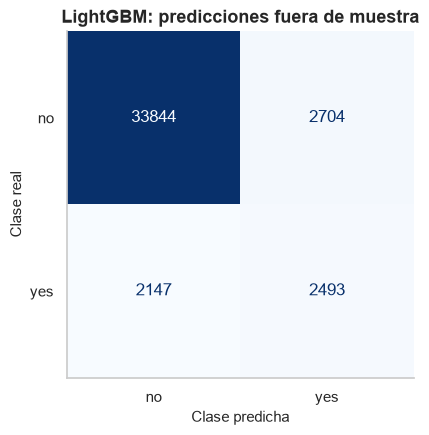

              precision    recall  f1-score   support

          no      0.940     0.926     0.933     36548
         yes      0.480     0.537     0.507      4640

    accuracy                          0.882     41188
   macro avg      0.710     0.732     0.720     41188
weighted avg      0.888     0.882     0.885     41188

Comparacion por pares contra: LightGBM


,modelo,diferencia media,desv. de la diferencia,pliegues ganados (de 5)
0,Random Forest,-0.0002,0.0017,2
1,Votacion suave RF+XGB+LGBM + umbral,-0.0003,0.0025,2
2,Random Forest (500 arboles),-0.0005,0.0019,2
3,LightGBM + umbral,-0.0007,0.0015,2
4,Stacking (meta con pesos 1:3),-0.0008,0.0021,1
5,Votacion dura,-0.0009,0.0015,1


In [25]:
mejor_banco = tabla_banco.iloc[0]["modelo"]
modelo_banco = BANCO["tabla"][mejor_banco]["estimador"]
pred_banco = cross_val_predict(modelo_banco, X_banco, y_banco, cv=CV_BANCO, n_jobs=-1)

ConfusionMatrixDisplay.from_predictions(y_banco, pred_banco, display_labels=["no", "yes"], cmap=CMAP_CONF, colorbar=False)
plt.grid(False)
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.title(f"{mejor_banco}: predicciones fuera de muestra")
mostrar("8_7_matriz_confusion_banco")

print(classification_report(y_banco, pred_banco, target_names=["no", "yes"], digits=3))

f1_ref_b = BANCO["tabla"][mejor_banco]["f1"]
filas = []
for nombre in tabla_banco["modelo"].iloc[1:7]:
    dif = BANCO["tabla"][nombre]["f1"] - f1_ref_b
    filas.append([nombre, dif.mean(), dif.std(), (dif > 0).sum()])
print("Comparacion por pares contra:", mejor_banco)
pd.DataFrame(filas, columns=["modelo", "diferencia media", "desv. de la diferencia", "pliegues ganados (de 5)"])

**Qué hace el código.**

- Dibuja la matriz de confusión fuera de muestra del mejor modelo y su reporte por clase.
- Compara por pares a los seis siguientes modelos contra el mejor, para ver si la diferencia es real o solo ruido entre pliegues.

**Lectura.** **LightGBM queda en primer lugar, pero es un empate técnico:** Random Forest queda a −0.0002 ± 0.0017 y le gana en 2 de los 5 pliegues, y a tres decimales los dos dan 0.720. LightGBM tiene además una ventaja práctica: entrena unas 4.5 veces más rápido (3.1 s contra 14.0 s por pliegue), aunque ese tiempo depende de la carga de la computadora durante la búsqueda.

En términos del negocio, de los 5197 clientes que el modelo manda a llamar, 2493 aceptan. Eso es un **48.0 % de precisión contra el 11.3 % de la base, unas 4.3 veces más**, y alcanza al 53.7 % de todos los clientes que aceptarían. Hay que recordar que este modelo optimiza el F1 macro, no la ganancia del banco. Con los costos de la Tarea 4 (umbral económico de 0.10), al banco le convendría llamar a mucha más gente.

### 8.8 Verificación con la llamada del enunciado y modelo guardado

El enunciado fija exactamente cómo se debe calcular el F1 macro de cada modelo, para que los resultados de todos sean comparables. Aquí se repite esa llamada, tal cual, con el mejor modelo, y se comprueba que da lo mismo que la tabla. Después el modelo se entrena con las 41 188 llamadas y se guarda con `joblib`.

In [26]:
def sin_envoltura(modelo):
    """Cambia ConPesos por el modelo de la libreria con el mismo peso, para que el .joblib no dependa del notebook"""
    final = clone(modelo)
    paso = final.named_steps.get("modelo") if isinstance(final, Pipeline) else None
    if isinstance(paso, ConPesos):
        estimador, pesos = clone(paso.estimador), paso.class_weight
        if isinstance(estimador, LGBMClassifier):
            estimador.set_params(class_weight=pesos)
        elif isinstance(estimador, XGBClassifier) and isinstance(pesos, dict):
            estimador.set_params(scale_pos_weight=pesos[1] / pesos[0])
        elif pesos is not None:
            raise ValueError(f"No se puede quitar ConPesos con class_weight={pesos}")
        final.set_params(modelo=estimador)
    return final

modelo_final = sin_envoltura(modelo_banco)
r = cross_validate(modelo_final, X_banco, y_banco, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=2026),
                   scoring="f1_macro")
print(f"{mejor_banco}: F1 macro = {r['test_score'].mean():.4f} +- {r['test_score'].std():.4f}")
assert np.allclose(r["test_score"], BANCO["tabla"][mejor_banco]["f1"])

ARCHIVO_MODELO = Path("Carlos-Campos_modelo.joblib")
modelo_final.fit(X_banco, y_banco)
joblib.dump(modelo_final, ARCHIVO_MODELO)

cargado = joblib.load(ARCHIVO_MODELO)
assert (cargado.predict(X_banco) == modelo_final.predict(X_banco)).all()
print(f"Guardado en {ARCHIVO_MODELO} ({ARCHIVO_MODELO.stat().st_size / 1e6:.1f} MB)")
modelo_final

LightGBM: F1 macro = 0.7200 +- 0.0061
Guardado en Carlos-Campos_modelo.joblib (2.3 MB)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['age','job','marital',...,'cons.conf.idx','euribor3m','nr.employed']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categoricos', ...), ('numericos', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``,

**Qué hace el código.**

- `sin_envoltura` cambia `ConPesos` por el mismo modelo con el peso nativo de la librería (`class_weight` en LightGBM y `scale_pos_weight` en XGBoost). Así, para cargar el archivo basta con tener las librerías instaladas, sin necesitar las clases definidas en este notebook.
- Evalúa ese modelo con `cross_validate(modelo, X, y, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=2026), scoring="f1_macro")` y comprueba que da los mismos cinco F1 de la tabla, es decir, que el cambio no altera el modelo.
- Lo entrena con las 41 188 llamadas y lo guarda en `Carlos-Campos_modelo.joblib`. El archivo contiene el pipeline completo, incluido el preprocesamiento: recibe las columnas del CSV sin `duration` ni `y` y predice 0 o 1.
- Lo vuelve a cargar para comprobar que predice exactamente lo mismo.

---

### 8.9 ¿Funcionó lo mismo que en la deserción?

Para responder esta pregunta se ponen lado a lado los efectos de los mismos cambios en los dos conjuntos de datos.

In [27]:
def media(datos, nombre):
    return datos["tabla"][nombre]["f1"].mean()

filas = [
    ["Arbol sin limite → bagging", media(DESERCION, "Arbol sin limite"), media(DESERCION, "Bagging (400 arboles)"),
     media(BANCO, "Arbol sin limite"), media(BANCO, "Bagging (100 arboles)")],
    ["Tocon → AdaBoost", media(DESERCION, "Tocon"), media(DESERCION, "AdaBoost (400 tocones)"),
     media(BANCO, "Tocon"), media(BANCO, "AdaBoost (400 tocones)")],
    ["Sin balanceo → class_weight (logistica)", np.nan, media(DESERCION, "Regresion logistica"),
     media(BANCO, "LR: sin balanceo"), media(BANCO, "LR: class_weight")],
    ["class_weight → umbral optimizado (logistica)", np.nan, np.nan,
     media(BANCO, "LR: class_weight"), media(BANCO, "LR: umbral optimizado")],
    ["SVM de P3 → XGBoost optimizado", media(DESERCION, "SVM"), media(DESERCION, "XGBoost"),
     media(BANCO, "SVM (P3)"), media(BANCO, "XGBoost")],
    ["Regresion logistica → Random Forest optimizado", media(DESERCION, "Regresion logistica"), media(DESERCION, "Random Forest"),
     media(BANCO, "LR: class_weight"), media(BANCO, "Random Forest")],
]
pd.DataFrame(filas, columns=["cambio", "desercion: antes", "desercion: despues", "banco: antes", "banco: despues"])

,cambio,desercion: antes,desercion: despues,banco: antes,banco: despues
0,Arbol sin limite → bagging,0.5890,0.6577,0.6180,0.6670
1,Tocon → AdaBoost,0.4920,0.6308,0.4702,0.6251
2,Sin balanceo → class_weight (logistica),NaN,0.6854,0.6424,0.6741
3,class_weight → umbral optimizado (logistica),NaN,NaN,0.6741,0.7080
4,SVM de P3 → XGBoost optimizado,0.6820,0.6991,0.6969,0.7187
5,Regresion logistica → Random Forest optimizado,0.6854,0.6835,0.6741,0.7198


**Qué hace el código.**

- Reúne en una tabla el F1 antes y después de cada cambio (agregar bagging, agregar boosting, balancear, ajustar el umbral y optimizar) en los dos conjuntos.

**Lectura. ¿Funcionó lo mismo que en la deserción, y por qué?** Los mecanismos sí funcionaron igual, pero lo que más importó fue distinto.

**Lo que funcionó igual.** Bagging volvió a reducir la varianza sin mejorar la clase minoritaria, y boosting volvió a reducir el sesgo de los tocones. Combinar modelos tampoco ganó casi nada en ninguno de los dos conjuntos, porque los modelos fuertes tienden a fallar en los mismos casos. Incluso la ganancia del mejor ensamble sobre la mejor regresión logística es parecida: +0.014 en deserción y +0.012 en el banco (0.7200 contra 0.7080, con el umbral también ajustado). Y en los dos conjuntos las búsquedas llegan muy pronto a una meseta, lo que sugiere que el límite está más en la información que tienen los atributos que en el modelo.

**Lo que cambió.**

- **`balanced` ya no es lo mejor.** En deserción lo eligieron todos los modelos optimizados; en el banco queda ≈ 0.02–0.03 por debajo del peso 1:3. Con solo 11.3 % de `yes` y poca señal, `balanced` (≈ 7.9) genera demasiadas falsas alarmas, y el F1 de `yes` castiga la mala precisión tanto como la mala sensibilidad. Además, en un problema binario hay una sola frontera que mover, por lo que un umbral la ajusta directamente; con tres clases no existe un único umbral.
- **Los hiperparámetros no se transfieren.** El XGBoost de deserción logra 0.694 en el banco, y una vez reoptimizado llega a 0.719.
- **Las estimaciones son más estables.** Con 12 veces más datos, la desviación entre pliegues baja de ≈ 0.02 a ≈ 0.006. Aun así, los mejores modelos siguen sin distinguirse, porque sus diferencias son todavía más pequeñas.
- **El costo pesa más.** El SVM pasa de ser tan rápido como la logística a ser, por mucho, el modelo más lento.

---

## 9. Conclusiones

La pregunta de la práctica era **¿cuánto ganan los ensambles sobre modelos base bien ajustados?** La respuesta, en los dos conjuntos de datos, es: **poco**. En deserción, el mejor ensamble (XGBoost, 0.6991) le gana +0.014 ± 0.012 de F1 macro a la regresión logística de la Práctica 3 (0.6854). Además, ese valor se seleccionó entre 60 configuraciones y está aislado de las siguientes (0.6924), así que probablemente es algo optimista. En Bank Marketing, el mejor modelo (LightGBM, 0.7200) le gana +0.012 a la logística con umbral optimizado (0.7080). En los dos problemas, una decena de modelos distintos termina en una meseta muy estrecha.

### Qué aportó cada familia en los dos problemas

| Familia | Deserción estudiantil | Bank Marketing |
|---|---|---|
| **Bagging** | Árbol sin límite → bagging: 0.589 → 0.658. Random Forest optimizado: 0.684, por debajo de la logística | Árbol sin límite → bagging: 0.618 → 0.667. Random Forest optimizado: 0.720, empatado en el primer lugar |
| **Boosting** | Tocón → AdaBoost: 0.492 → 0.631. XGBoost optimizado: 0.699, el mejor | Tocón → AdaBoost: 0.470 → 0.625. LightGBM optimizado: 0.720, el mejor |
| **Votación y stacking** | Solo el stacking con meta-modelo `balanced` alcanza a la logística (0.687) | Ninguna combinación supera a sus componentes (0.718–0.720) |
| **Balanceo y decisión** | `class_weight="balanced"` fue lo mejor en todos los modelos optimizados | `balanced` queda ≈ 0.02–0.03 abajo. Lo mejor es un peso 1:3 o un umbral optimizado; la logística pasa de 0.642 a 0.708 solo con el umbral |

**Bagging** cumplió lo que se esperaba en los dos problemas: reduce la varianza. En deserción, el desacuerdo entre réplicas bajó de 33.7 % a 9.6 % sin que el F1 de entrenamiento cambiara (1.0). Lo que no hizo, en ninguno de los dos, fue mejorar la clase minoritaria, porque promediar árboles no compensa el desbalance.

**Boosting** también cumplió su papel: reduce el sesgo. Los tocones subieron juntos en entrenamiento y validación (0.492 → 0.657 y 0.631 en deserción). Una vez optimizado, el boosting quedó en primer lugar en los dos conjuntos, aunque con un margen que no se distingue del ruido entre pliegues.

**Combinar modelos casi no ayudó**, porque los modelos fallan en los mismos casos. En deserción, la correlación media de los errores es de 0.54, y los cinco modelos base fallan juntos en el 12 % de los estudiantes, 55 veces más de lo esperado si fueran independientes. En el banco, los modelos de árboles optimizados ya son prácticamente intercambiables.

Otros dos hallazgos de la Parte 1 vale la pena destacar. Primero, **calibrar tiene un costo que no se ve a primera vista**: deshace buena parte de `class_weight` y baja la sensibilidad de `enrolled` del SVM de 0.581 a 0.307. Segundo, ***enrolled* sigue siendo la clase difícil**: XGBoost deja su F1 en 0.490, igual que en la Práctica 3, y lo que gana viene de `dropout` y `graduate`.

En **Bank Marketing**, el mejor modelo es **LightGBM con peso 1:3** (F1 macro = 0.7200 ± 0.0061, sensibilidad de `yes` = 0.537), empatado a tres decimales con Random Forest (0.7198). Sus llamadas aciertan 4.3 veces más que la tasa base, y quedó guardado en `Carlos-Campos_modelo.joblib`.

### Diferencias y qué características de los datos las explican

- **Desbalance y número de clases.** El banco tiene solo 11.3 % de `yes` y una sola frontera de decisión. Por eso mover la decisión (con un peso moderado o un umbral) importó más que el tipo de ensamble. Deserción tiene tres clases y la minoritaria representa el 17.9 %, así que no existe un umbral único y `balanced` es el que hace ese trabajo.
- **Tamaño.** Con 12 veces más datos, la desviación entre pliegues baja de ≈ 0.02 a ≈ 0.006, y los modelos flexibles (Random Forest y boosting con más hojas) aprovechan mejor la información: en el banco, los árboles superan a la logística por ≈ 0.012 incluso después de ajustar su umbral. El costo también crece: el SVM pasó de 0.5 s a 143 s por pliegue.
- **Tipo de atributos.** En deserción, la señal fuerte está en pocos atributos numéricos del 1er semestre (unidades aprobadas y calificación) con relaciones casi monótonas, que un modelo lineal captura bien; por eso la logística compite con todos los ensambles. En el banco dominan las variables categóricas y los indicadores macroeconómicos (`euribor3m`, `nr.employed`), que toman pocos valores y marcan periodos de tiempo. Los árboles representan mejor ese tipo de cortes y sus interacciones.
- **Límite de información.** En los dos problemas, las búsquedas llegan pronto a una meseta y los errores están correlacionados entre modelos. Esto indica que lo que falta es información en los atributos (en deserción, el desempeño del 2.º semestre; en el banco, `duration`, que no se puede usar), no capacidad del modelo.

### Limitaciones

- **Sesgo de selección:** en los dos conjuntos, las búsquedas y la evaluación usan los mismos pliegues, así que los F1 de los modelos optimizados son algo optimistas. Una validación cruzada anidada lo corregiría, a cambio de mucho más cómputo.
- **Pocos pliegues:** con solo 5 pliegues, las comparaciones por pares son orientativas y no una prueba estadística formal.
- **Tiempo en el banco:** `bank-additional-full.csv` está ordenado por fecha, y atributos como `euribor3m` o `nr.employed` cambian con el periodo. Con pliegues barajados, como pide el enunciado, el modelo entrena con llamadas posteriores a las que evalúa; en un uso real, al predecir meses futuros, el F1 podría ser menor.
- **Filas repetidas:** las 1784 filas repetidas del banco pueden caer a ambos lados de un pliegue.

---

## 10. Referencias

Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research, 13*, 281–305.

Breiman, L. (1996). Bagging predictors. *Machine Learning, 24*(2), 123–140.

Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32.

Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE: Synthetic minority over-sampling technique. *Journal of Artificial Intelligence Research, 16*, 321–357.

Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. En *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining* (pp. 785–794).

Freund, Y., & Schapire, R. E. (1997). A decision-theoretic generalization of on-line learning and an application to boosting. *Journal of Computer and System Sciences, 55*(1), 119–139.

Geurts, P., Ernst, D., & Wehenkel, L. (2006). Extremely randomized trees. *Machine Learning, 63*(1), 3–42.

Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. En *Advances in Neural Information Processing Systems 30* (pp. 3146–3154).

Moro, S., Cortez, P., & Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. *Decision Support Systems, 62*, 22–31.

Realinho, V., Vieira Martins, M., Machado, J., & Baptista, L. (2021). *Predict students' dropout and academic success* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89

Wolpert, D. H. (1992). Stacked generalization. *Neural Networks, 5*(2), 241–259.

---

## 11. Declaración de uso de IA

Se utilizó **Claude Opus 5.5 (Anthropic, mediante Claude Code)** como asistente durante esta práctica.